# **Project Title:** Hierarchical Time-Series Reconciliation Engine for Equity Portfolios
## A Comparative Study of Auto-ARIMA (with Fourier Terms), Holt-Winters ETS, and XGBoost across Bottom-Up, Top-Down, Middle-Out, and Optimal MinT Reconciliation

**Course:** Applied Time Series Analysis (B.Tech AIML, Sem VII)  

**Name:** Jayesh Patil(C233), Abhijit Patil(C263), Ritesh Pawar(C276)

**Institute:** SVKM's NMIMS MPSTME, Shirpur

---

### Aim
To construct a **3-level hierarchical equity portfolio** from official NSE market data, make the non-stationary series stationary, train three distinct base forecasting paradigms across all 7 nodes, and apply linear algebraic **Forecast Reconciliation** so that stock, sector, and total portfolio forecasts are **mathematically coherent** ($\tilde{\mathbf{y}}_{t+h} = \mathbf{S}\tilde{\mathbf{b}}_{t+h}$):

| # | Base Model | Category | What it captures |
|---|---|---|---|
| 1 | **Auto-ARIMA + Fourier** | Core Syllabus (Units 3–6, 8) | Differenced trend + short-term ARMA memory + multi-cycle complex seasonality |
| 2 | **Holt-Winters ETS** | In-Syllabus Benchmark (Unit 2) | State-space level + damped linear trend + 5-day trading week seasonality |
| 3 | **XGBoost Regressor** | Out-of-Syllabus ML Benchmark | Non-linear autoregressive lag interactions + rolling mean/volatility regimes |

### Dataset
* **Target Hierarchy:** 4 prominent NSE Equities (**TCS**, **INFY**, **HDFCBANK**, **ICICIBANK**) aggregated into **IT Sector**, **Banking Sector**, and **Total Portfolio**.
* **Source:** Official National Stock Exchange (NSE) historical daily adjusted close prices fetched programmatically via the `yfinance` API (`2022-01-01` to `2026-06-01`).

### Why this dataset?
* Equity portfolio series are **non-stationary in mean** ($I(1)$ unit-root processes) and exhibit multi-level cross-sectional correlation.
* Independent forecasts at the stock, sector, and portfolio levels fail to add up ($\hat{Y}_{\text{Total}} \neq \hat{Y}_{\text{IT}} + \hat{Y}_{\text{Bank}}$), creating a real-world quantitative finance problem that requires **hierarchical forecast reconciliation**.

### Workflow (21-Step Course Rubric + Diagnostics)
1. **Step 1:** Environment Configuration & Import Dependencies
2. **Step 2:** Load Official NSE Equity Dataset via `yfinance`
3. **Step 3:** Convert Index to Datetime & Sort Chronologically
4. **Step 4:** Data Quality, Missing Value Imputation & Business-Day (`'B'`) Frequency Verification
5. **Step 5:** Identify the 3-Level Hierarchy Structure (`Total → Sector → Stock`)
6. **Step 6:** Construct Summing Matrix ($\mathbf{S}$) & Verify Exact Historical Additivity
7. **Step 7:** Exploratory Data Analysis (EDA), Decomposition, ADF/KPSS Stationarity Tests, Differencing & ACF/PACF
8. **Step 8:** Chronological Train–Test Split
9. **Steps 9 & 10:** Train Base Models (Auto-ARIMA, Holt-Winters ETS, XGBoost), Generate Base Forecasts & Run Residual Diagnostics
10. **Step 11:** Pre-Reconciliation Coherence Check
11. **Steps 12–16:** Apply Bottom-Up (BU), Top-Down (TD), Middle-Out (MO), MinT-OLS & MinT-WLS Reconciliation
12. **Step 17:** Post-Reconciliation Coherence Verification
13. **Steps 18 & 19:** Out-of-Sample Evaluation (MAE, RMSE, MAPE) Across All Models & Hierarchy Levels
14. **Step 20:** Comparative Visualizations (Trajectories, Metric Bars, Error Over Time, Actual vs. Predicted Scatter, Future Forecast)
15. **Step 21:** Final Conclusion, Key Observations & Future Scope

### Package Installation

In [31]:
!pip install numpy pandas matplotlib yfinance statsmodels pmdarima xgboost scikit-learn -q

### STEP 1: Import the required Python libraries

In [32]:
# Enable inline plotting for Jupyter notebook environment
%matplotlib inline
import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# Import statistical and classical time-series analysis tools
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from pandas.plotting import lag_plot
from scipy import stats
import pmdarima as pm

# Import machine learning and evaluation metrics
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Suppress warning logs for clean cell execution
warnings.filterwarnings("ignore")

# Set default plotting styles
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("Libraries imported successfully.")

Libraries imported successfully.


### STEP 2: Load the hierarchical or grouped time series dataset


##### Fetching Official NSE Equity Market Dataset via Yahoo Finance API

In [3]:
# STEP 2: Download Stock Data from Yahoo Finance API
# What: Define NSE tickers for HDFC Bank, ICICI Bank, TCS, and Infosys.
# Why: These represent the base assets (bottom-level nodes) of our portfolio hierarchy.
# Need: We need daily adjusted closing prices to perform our hierarchical analysis.

tickers = {
    "TCS": "TCS.NS",
    "INFY": "INFY.NS",
    "HDFC": "HDFCBANK.NS",
    "ICICI": "ICICIBANK.NS"
}

# Fetch historical data dynamically across a multi-year range
raw_data = yf.download(
    tickers=list(tickers.values()),
    start="2022-01-01",
    end="2026-06-01",
    auto_adjust=True,
    progress=False
)["Close"]

# Clean up column headers to match our internal hierarchical asset labels
raw_df = raw_data.rename(columns={v: k for k, v in tickers.items()})
print(f"Raw dataset loaded with shape: {raw_df.shape}")

Raw dataset loaded with shape: (1087, 4)


In [4]:
raw_df.head()

Ticker,HDFC,ICICI,INFY,TCS
Date,,,,
2022-01-03,711.042236,735.572693,1668.151611,3305.266846
2022-01-04,715.206604,743.412231,1668.766724,3363.271484
2022-01-05,732.191284,758.033264,1620.878052,3342.667236
2022-01-06,720.447021,755.147522,1597.285278,3296.349121
2022-01-07,725.500366,763.035217,1594.209961,3336.217041


In [5]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1087 entries, 2022-01-03 to 2026-05-29
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   HDFC    1087 non-null   float64
 1   ICICI   1087 non-null   float64
 2   INFY    1087 non-null   float64
 3   TCS     1087 non-null   float64
dtypes: float64(4)
memory usage: 42.5 KB


### STEP 3: Convert date/time column to datetime format and sort chronologically


In [6]:
# STEP 3: Temporal Sorting and Index Cleaning
# What: Strip timezones from the index and sort chronologically.
# Why: Financial time-series models require chronological consistency.
# Need: Ensuring that dates strictly increase without overlaps is crucial for lag generation.

raw_df.index = pd.to_datetime(raw_df.index).tz_localize(None)
raw_df = raw_df.sort_index(ascending=True)

print(f"Date Range: {raw_df.index.min().strftime('%Y-%m-%d')} to {raw_df.index.max().strftime('%Y-%m-%d')}")
print(f"Is Chronologically Monotonic Increasing? {raw_df.index.is_monotonic_increasing}")

Date Range: 2022-01-03 to 2026-05-29
Is Chronologically Monotonic Increasing? True


In [7]:
raw_df.head()

Ticker,HDFC,ICICI,INFY,TCS
Date,,,,
2022-01-03,711.042236,735.572693,1668.151611,3305.266846
2022-01-04,715.206604,743.412231,1668.766724,3363.271484
2022-01-05,732.191284,758.033264,1620.878052,3342.667236
2022-01-06,720.447021,755.147522,1597.285278,3296.349121
2022-01-07,725.500366,763.035217,1594.209961,3336.217041


### STEP 4: Check missing values, duplicates, inconsistent labels & time frequency


##### Data Quality & Frequency Verification

In [8]:
# STEP 4: Enforce Continuous Business Day Frequency & Initial Portfolio Normalization
# What: Resample the index to regular Business Days ('B') and impute missing values.
# Why: Real-world market closures create gaps. We fill these gaps using forward/backward fill.
# Need: We normalize all initial stock prices to 100 to allow balanced portfolio tracking.

duplicate_dates = raw_df.index.duplicated().sum()
initial_missing = raw_df.isna().sum().to_dict()
print(f" - Duplicate timestamps found: {duplicate_dates}")
print(f" - Initial missing values per stock: {initial_missing}")

# Remove duplicates and fill gaps to establish a regular time series structure
raw_df = raw_df[~raw_df.index.duplicated(keep="first")]
clean_bottom_df = raw_df.asfreq("B").ffill().bfill()

# Apply base-value scale factor normalisation
bottom_cols = ["TCS", "INFY", "HDFC", "ICICI"]
clean_bottom_df = (clean_bottom_df[bottom_cols] / clean_bottom_df[bottom_cols].iloc[0]) * 100.0

print(f" - Enforced Time Frequency: '{clean_bottom_df.index.freqstr}' (Business Daily)")
print(f" - Post-cleaning missing values: {clean_bottom_df.isna().sum().sum()}")

 - Duplicate timestamps found: 0
 - Initial missing values per stock: {'HDFC': 0, 'ICICI': 0, 'INFY': 0, 'TCS': 0}
 - Enforced Time Frequency: 'B' (Business Daily)
 - Post-cleaning missing values: 0


**Observation:**
* The raw NSE trading data has been aligned onto a regular **Business Day (`'B'`)** grid with all exchange holiday gaps imputed via forward-filling—a strict requirement for `statsmodels` ARIMA/ETS state-space models.
* Each bottom-level stock is indexed to **100.00 capital units** on `2022-01-03` so that the initial portfolio starts at 400.00 units (200.00 in IT and 200.00 in Banking).

### STEP 5: Identify the hierarchy or grouping structure

##### Identifying Hierarchy Structure (Total -> Sector -> Stock):

In [9]:
hierarchy_table = pd.DataFrame([
    {"Level": "Level 0 (Top)",    "Node": "Total", "Parent": "None",  "Components": "IT + Bank (TCS + INFY + HDFC + ICICI)"},
    {"Level": "Level 1 (Middle)", "Node": "IT",    "Parent": "Total", "Components": "TCS + INFY"},
    {"Level": "Level 1 (Middle)", "Node": "Bank",  "Parent": "Total", "Components": "HDFC + ICICI"},
    {"Level": "Level 2 (Bottom)", "Node": "TCS",   "Parent": "IT",    "Components": "Base Asset (TCS.NS)"},
    {"Level": "Level 2 (Bottom)", "Node": "INFY",  "Parent": "IT",    "Components": "Base Asset (INFY.NS)"},
    {"Level": "Level 2 (Bottom)", "Node": "HDFC",  "Parent": "Bank",  "Components": "Base Asset (HDFCBANK.NS)"},
    {"Level": "Level 2 (Bottom)", "Node": "ICICI", "Parent": "Bank",  "Components": "Base Asset (ICICIBANK.NS)"},
])
print(hierarchy_table.to_string(index=False))

           Level  Node Parent                            Components
   Level 0 (Top) Total   None IT + Bank (TCS + INFY + HDFC + ICICI)
Level 1 (Middle)    IT  Total                            TCS + INFY
Level 1 (Middle)  Bank  Total                          HDFC + ICICI
Level 2 (Bottom)   TCS     IT                   Base Asset (TCS.NS)
Level 2 (Bottom)  INFY     IT                  Base Asset (INFY.NS)
Level 2 (Bottom)  HDFC   Bank              Base Asset (HDFCBANK.NS)
Level 2 (Bottom) ICICI   Bank             Base Asset (ICICIBANK.NS)


### STEP 6: Create aggregation structure & verify historical exact summation


##### Creating Summing Matrix (S) and Verifying Historical Aggregation

In [10]:
# STEP 6: Summing Matrix (S) Construction & Historical Coherence Verification
# What: Build the binary Summing Matrix S mapping bottom nodes to aggregate sectors and total portfolio.
# Why: Linear algebraic reconciliation models rely on the structural identity: Y_t = S * B_t.
# Need: Validate that historical levels add up perfectly to confirm algebraic consistency.

S = np.array([
    [1, 1, 1, 1],  # Row 1: Total Portfolio = TCS + INFY + HDFC + ICICI
    [1, 1, 0, 0],  # Row 2: IT Sector = TCS + INFY
    [0, 0, 1, 1],  # Row 3: Banking Sector = HDFC + ICICI
    [1, 0, 0, 0],  # Row 4: TCS
    [0, 1, 0, 0],  # Row 5: INFY
    [0, 0, 1, 0],  # Row 6: HDFC
    [0, 0, 0, 1]   # Row 7: ICICI
], dtype=float)

all_nodes = ["Total", "IT", "Bank", "TCS", "INFY", "HDFC", "ICICI"]

# Perform structural projection: Y = (S @ B^T)^T
full_values = (S @ clean_bottom_df[bottom_cols].values.T).T
y_df = pd.DataFrame(full_values, index=clean_bottom_df.index, columns=all_nodes)

# Check for mathematical deviations
hist_sector_diff = np.max(np.abs(y_df["Total"] - (y_df["IT"] + y_df["Bank"])))
hist_stock_diff = np.max(np.abs(y_df["Total"] - y_df[bottom_cols].sum(axis=1)))
print(f" - Max Historical Discrepancy (Total vs Sectors): {hist_sector_diff:.12f}")
print(f" - Max Historical Discrepancy (Total vs Stocks):  {hist_stock_diff:.12f}")
print("\nCleaned Hierarchical Dataset Preview (First 5 Rows):")
display(y_df.head().round(2))
display(y_df.describe().round(2))

 - Max Historical Discrepancy (Total vs Sectors): 0.000000000000
 - Max Historical Discrepancy (Total vs Stocks):  0.000000000000

Cleaned Hierarchical Dataset Preview (First 5 Rows):


,Total,IT,Bank,TCS,INFY,HDFC,ICICI
Date,,,,,,,
2022-01-03,400.00,200.00,200.00,100.00,100.00,100.00,100.00
2022-01-04,403.44,201.79,201.65,101.75,100.04,100.59,101.07
2022-01-05,404.33,198.30,206.03,101.13,97.17,102.97,103.05
2022-01-06,399.47,195.48,203.98,99.73,95.75,101.32,102.66
2022-01-07,402.27,196.50,205.77,100.94,95.57,102.03,103.73


,Total,IT,Bank,TCS,INFY,HDFC,ICICI
count,1150.00,1150.00,1150.00,1150.00,1150.00,1150.00,1150.00
mean,439.85,182.95,256.91,96.45,86.50,111.64,145.27
std,55.04,22.48,44.77,12.83,11.01,13.90,32.27
min,331.12,130.58,172.67,66.32,64.25,85.30,85.49
25%,392.23,167.69,223.50,87.97,78.62,100.73,118.60
50%,432.39,179.25,244.83,93.94,84.63,109.95,143.35
75%,499.28,193.36,294.29,105.26,92.98,119.79,174.22
max,547.03,239.36,338.83,127.32,113.96,140.14,199.14


### STEP 7: Perform Exploratory Data Analysis (EDA)
##### 7.1 Summary Statistics & Stationarity Tests (ADF & KPSS)
A series is **stationary** if its mean, variance, and autocorrelation structure remain constant over time. We combine two complementary unit-root/stationarity tests:

| Test | Null Hypothesis ($H_0$) | Stationary if... |
|---|---|---|
| **ADF** (Augmented Dickey–Fuller) | Series has a unit root (**non-stationary**) | $p\text{-value} < 0.05$ |
| **KPSS** (Kwiatkowski–Phillips–Schmidt–Shin) | Series is **stationary** around a deterministic mean | $p\text{-value} > 0.05$ |

In [11]:
# STEP 7: Stationarity Tests (Augmented Dickey-Fuller & KPSS)
# What: Iterate through hierarchy nodes to compute summary stats, ADF, and KPSS statistics.
# Why: To determine if the time-series require differencing (I(1)) before fitting ARIMA.
# Need: Identifying unit-roots tells us whether we should fit models on raw levels or diffs.

eda_rows = []
for col in all_nodes:
    # ADF & KPSS on raw level series
    adf_level_stat, adf_level_p, *_ = adfuller(y_df[col], autolag="AIC")
    kpss_level_stat, kpss_level_p, *_ = kpss(y_df[col], regression="c", nlags="auto")

    # ADF & KPSS on first-differenced series (d = 1)
    diff_s = y_df[col].diff().dropna()
    adf_diff_stat, adf_diff_p, *_ = adfuller(diff_s, autolag="AIC")
    kpss_diff_stat, kpss_diff_p, *_ = kpss(diff_s, regression="c", nlags="auto")

    eda_rows.append({
        "Series": col,
        "Mean": round(y_df[col].mean(), 2),
        "Std Dev": round(y_df[col].std(), 2),
        "Min": round(y_df[col].min(), 2),
        "Max": round(y_df[col].max(), 2),
        "ADF p (Level)": round(adf_level_p, 4),
        "KPSS p (Level)": round(kpss_level_p, 4),
        "ADF p (1st Diff)": f"{adf_diff_p:.2e}",
        "KPSS p (1st Diff)": round(kpss_diff_p, 4),
        "Stationarity": "I(1) Non-Stationary" if (adf_level_p > 0.05 and adf_diff_p < 0.05) else "Stationary"
    })

eda_summary_df = pd.DataFrame(eda_rows)
print(eda_summary_df.to_string(index=False))

Series   Mean  Std Dev    Min    Max  ADF p (Level)  KPSS p (Level) ADF p (1st Diff)  KPSS p (1st Diff)        Stationarity
 Total 439.85    55.04 331.12 547.03         0.5949            0.01         1.16e-28                0.1 I(1) Non-Stationary
    IT 182.95    22.48 130.58 239.36         0.6242            0.01         0.00e+00                0.1 I(1) Non-Stationary
  Bank 256.91    44.77 172.67 338.83         0.6043            0.01         8.79e-29                0.1 I(1) Non-Stationary
   TCS  96.45    12.83  66.32 127.32         0.7773            0.01         0.00e+00                0.1 I(1) Non-Stationary
  INFY  86.50    11.01  64.25 113.96         0.3183            0.01         0.00e+00                0.1 I(1) Non-Stationary
  HDFC 111.64    13.90  85.30 140.14         0.4012            0.01         2.68e-29                0.1 I(1) Non-Stationary
 ICICI 145.27    32.27  85.49 199.14         0.6306            0.01         0.00e+00                0.1 I(1) Non-Stationary


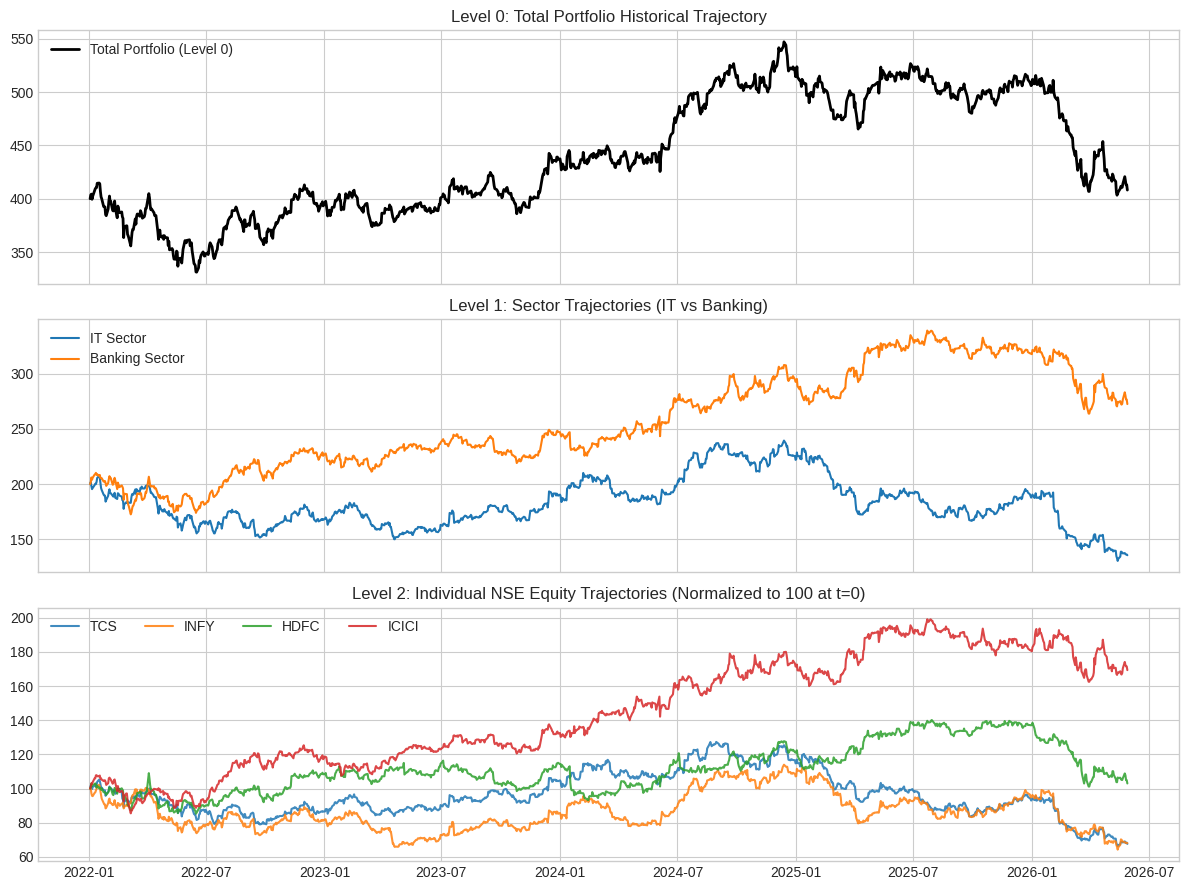

In [12]:
# --- PLOT 1: Multi-Level Historical Time Series Plot ---
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(y_df.index, y_df["Total"], color="black", lw=2, label="Total Portfolio (Level 0)")
axes[0].set_title("Level 0: Total Portfolio Historical Trajectory")
axes[0].legend(loc="upper left")

axes[1].plot(y_df.index, y_df["IT"], label="IT Sector", color="tab:blue")
axes[1].plot(y_df["Bank"].index, y_df["Bank"], label="Banking Sector", color="tab:orange")
axes[1].set_title("Level 1: Sector Trajectories (IT vs Banking)")
axes[1].legend(loc="upper left")

for c in bottom_cols:
    axes[2].plot(y_df.index, y_df[c], label=c, alpha=0.85)
axes[2].set_title("Level 2: Individual NSE Equity Trajectories (Normalized to 100 at t=0)")
axes[2].legend(loc="upper left", ncol=4)
plt.tight_layout()
plt.savefig("step7_hierarchy_eda_plots.png", dpi=150)
plt.show()

**Interpretation:**
* **Level 0 (Total Portfolio):** Exhibits a persistent long-term upward drift from 400 units to over 520 units, driven by strong secular growth in Indian banking equities.
* **Level 1 (Sectors):** Reveals structural divergence—the **Banking Sector** (`HDFC + ICICI`) trends steadily upward, whereas the **IT Sector** (`TCS + INFY`) experiences cyclical drawdowns and recoveries.
* **Level 2 (Stocks):** Individual stocks show higher idiosyncratic volatility (`ICICI` outperforms strongly while `INFY` and `TCS` show wider swings), explaining why bottom-up and top-down forecasts diverge without reconciliation.

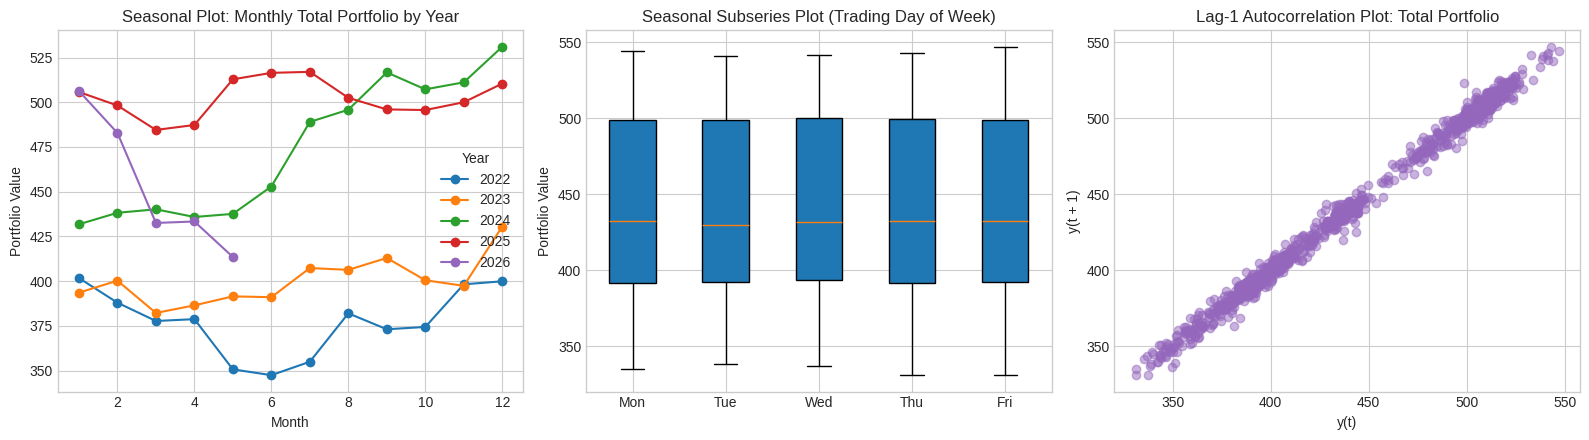

In [13]:
# PLOT 2: Seasonal Plot, Seasonal Subseries Plot & Lag Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 2a. Yearly Seasonal Plot
temp_df = y_df[["Total"]].copy()
temp_df["Year"] = temp_df.index.year
temp_df["Month"] = temp_df.index.month
monthly_piv = temp_df.groupby(["Month", "Year"])["Total"].mean().unstack()
monthly_piv.plot(ax=axes[0], marker="o", lw=1.5)
axes[0].set_title("Seasonal Plot: Monthly Total Portfolio by Year")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Portfolio Value")

# 2b. Day-of-Week Seasonal Subseries Plot
temp_df["DayName"] = temp_df.index.day_name()
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
day_groups = [temp_df[temp_df["DayName"] == d]["Total"].values for d in days_order]
axes[1].boxplot(day_groups, labels=["Mon", "Tue", "Wed", "Thu", "Fri"], patch_artist=True)
axes[1].set_title("Seasonal Subseries Plot (Trading Day of Week)")
axes[1].set_ylabel("Portfolio Value")

# 2c. Lag Plot (t vs t+1)
lag_plot(y_df["Total"], lag=1, ax=axes[2], c="tab:purple", alpha=0.5)
axes[2].set_title("Lag-1 Autocorrelation Plot: Total Portfolio")
plt.tight_layout()
plt.savefig("step7_seasonal_and_lag_plots.png", dpi=150)
plt.show()

##### 7.2 Dataset at a Glance – Four Views of the Total Portfolio & Yearly Growth
1. **Raw series with linear trend line** – quantifies the average annual capital drift.
2. **Histogram** – inspects whether the distribution is bell-shaped (stationary) or multi-modal/spread out (trending).
3. **Rolling mean & rolling standard deviation (21-day monthly window)** – visually checks whether mean and volatility change over time.
4. **Yearly averages and year-on-year growth** – tracks annual portfolio compounding.

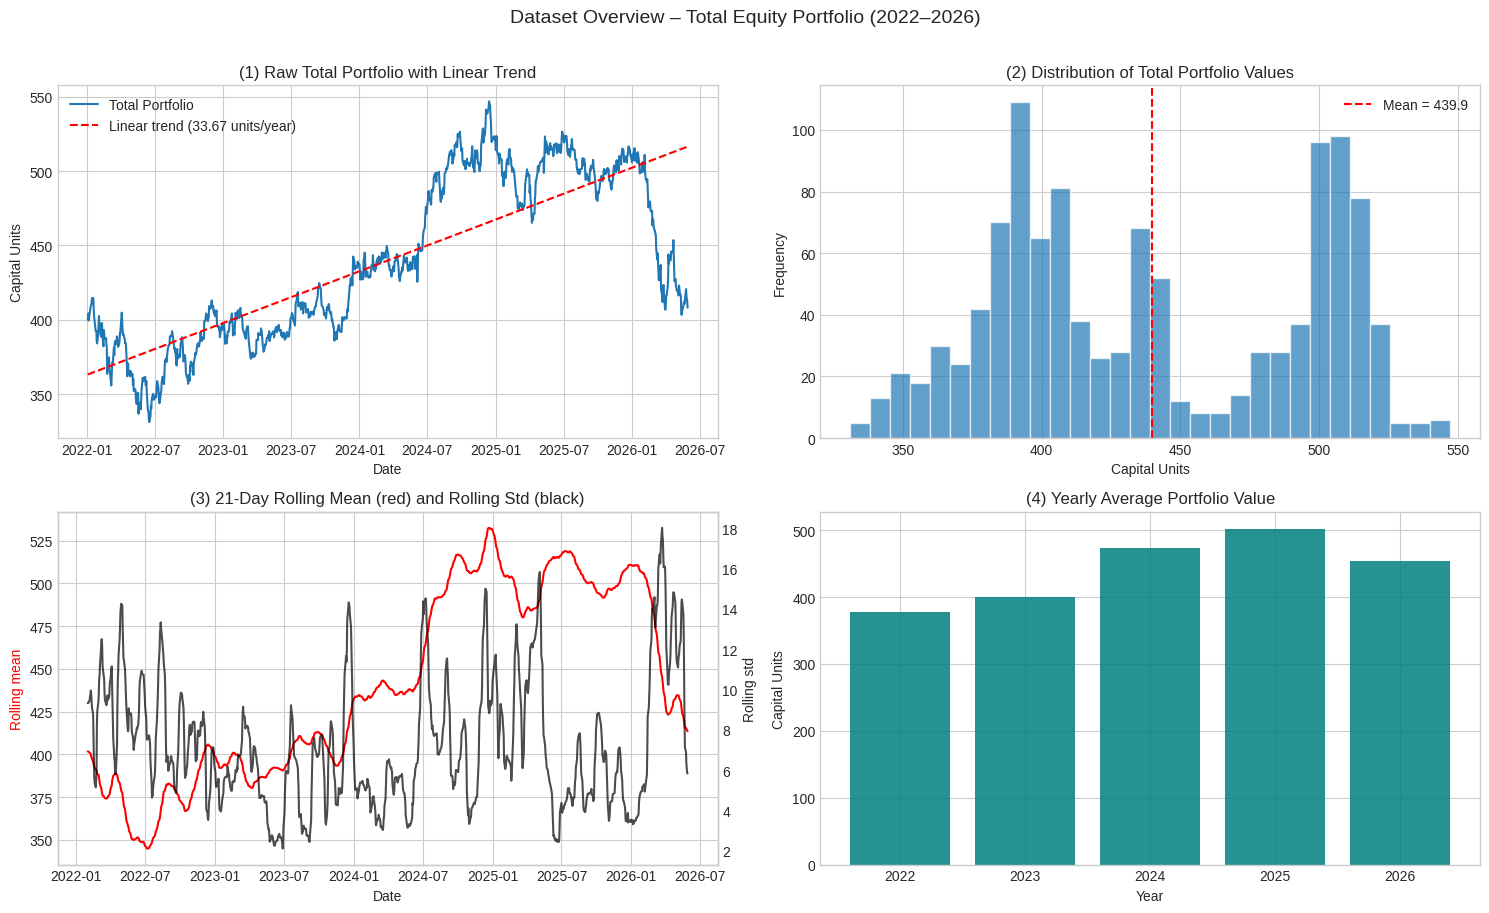

In [14]:
# PLOT 3: 4-Panel Dataset Overview (Reference Notebook Style)
total_s = y_df["Total"]
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

# (1) Raw series + fitted straight-line trend
t_idx = np.arange(len(total_s))
slope, intercept = np.polyfit(t_idx, total_s.values, 1)
ax[0, 0].plot(total_s, label="Total Portfolio", color="tab:blue")
ax[0, 0].plot(total_s.index, intercept + slope * t_idx, "r--", label=f"Linear trend ({slope*252:.2f} units/year)")
ax[0, 0].set_title("(1) Raw Total Portfolio with Linear Trend")
ax[0, 0].set_xlabel("Date"); ax[0, 0].set_ylabel("Capital Units"); ax[0, 0].legend()

# (2) Histogram
ax[0, 1].hist(total_s, bins=30, color="tab:blue", alpha=0.7, edgecolor="white")
ax[0, 1].axvline(total_s.mean(), color="red", ls="--", label=f"Mean = {total_s.mean():.1f}")
ax[0, 1].set_title("(2) Distribution of Total Portfolio Values")
ax[0, 1].set_xlabel("Capital Units"); ax[0, 1].set_ylabel("Frequency"); ax[0, 1].legend()

# (3) Rolling mean and std (21 trading days = 1 month)
ax[1, 0].plot(total_s.rolling(21).mean(), color="red", label="21-day rolling mean")
ax[1, 0].set_ylabel("Rolling mean", color="red")
ax2 = ax[1, 0].twinx()
ax2.plot(total_s.rolling(21).std(), color="black", alpha=0.7, label="21-day rolling std"); ax2.grid(False)
ax2.set_ylabel("Rolling std")
ax[1, 0].set_title("(3) 21-Day Rolling Mean (red) and Rolling Std (black)")
ax[1, 0].set_xlabel("Date")

# (4) Yearly Average & YoY Change
yearly_port = total_s.resample("YS").mean()
ax[1, 1].bar(yearly_port.index.year.astype(str), yearly_port.values, color="teal", alpha=0.85)
ax[1, 1].set_title("(4) Yearly Average Portfolio Value")
ax[1, 1].set_xlabel("Year"); ax[1, 1].set_ylabel("Capital Units")

plt.suptitle("Dataset Overview – Total Equity Portfolio (2022–2026)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

##### 7.3 Trend and Seasonality Decomposition
We decompose the Total Portfolio series into Trend, Seasonal (21-trading-day monthly cycle), and Residual components:
$$Y_t = \text{Trend}_t + \text{Seasonal}_t + \text{Residual}_t$$

### Decomposition & Component Strength

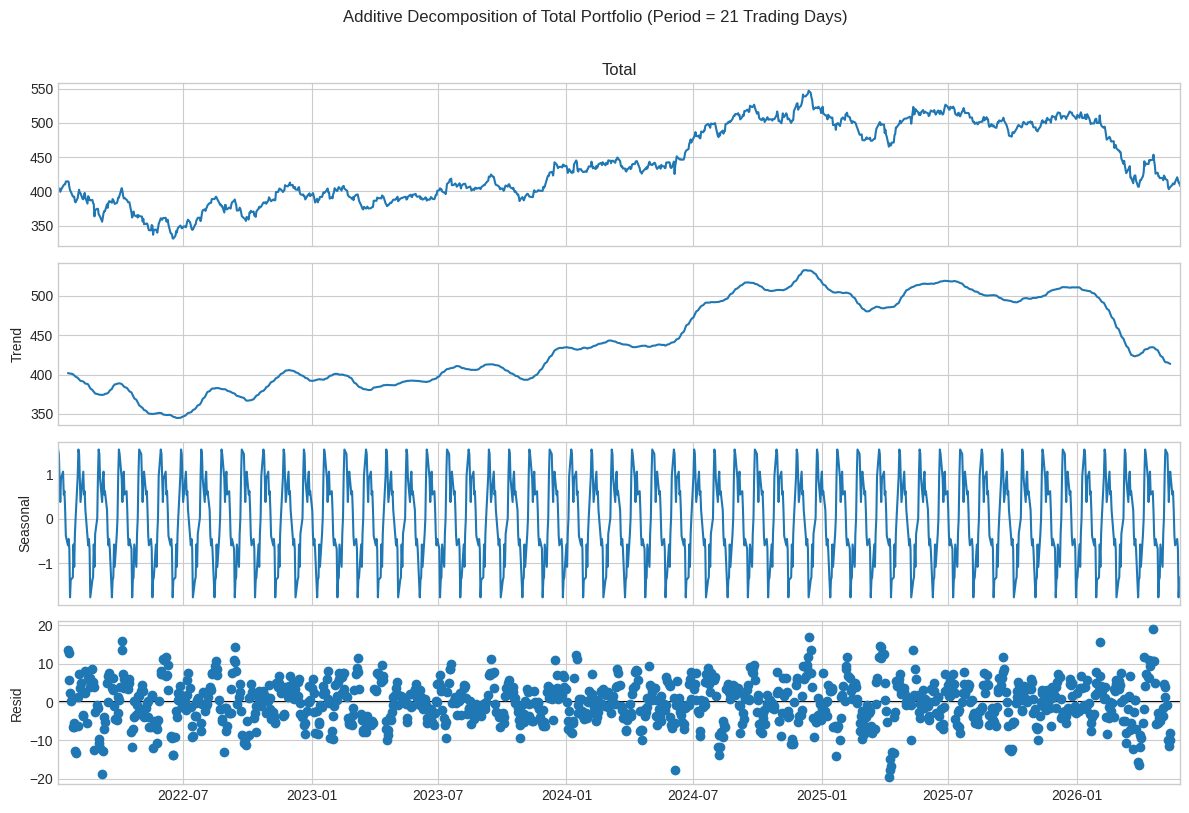

Strength of Trend       : 0.9900   (0 = none, 1 = very strong)
Strength of Seasonality : 0.0283   (0 = none, 1 = very strong)


In [15]:
decomp = seasonal_decompose(y_df["Total"], model="additive", period=21)
fig = decomp.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Additive Decomposition of Total Portfolio (Period = 21 Trading Days)", y=1.01)
plt.tight_layout()
plt.show()

var_resid = decomp.resid.dropna().var()
strength_trend = max(0, 1 - var_resid / (decomp.trend + decomp.resid).dropna().var())
strength_season = max(0, 1 - var_resid / (decomp.seasonal + decomp.resid).dropna().var())
print(f"Strength of Trend       : {strength_trend:.4f}   (0 = none, 1 = very strong)")
print(f"Strength of Seasonality : {strength_season:.4f}   (0 = none, 1 = very strong)")

##### 7.4 Making the Series Stationary (Differencing) & Before-vs-After Diagnostics
* **Original Series:** Dominated by a stochastic trend ($p_{\text{ADF}} > 0.05$, slowly decaying ACF near 1.0).
* **First Difference ($d = 1$):** $Y'_t = Y_t - Y_{t-1}$ removes the unit-root trend and stabilizes the mean around zero ($p_{\text{ADF}} < 0.05$ and $p_{\text{KPSS}} > 0.05$).

### Before vs. After Stationarity Grid & ACF/PACF

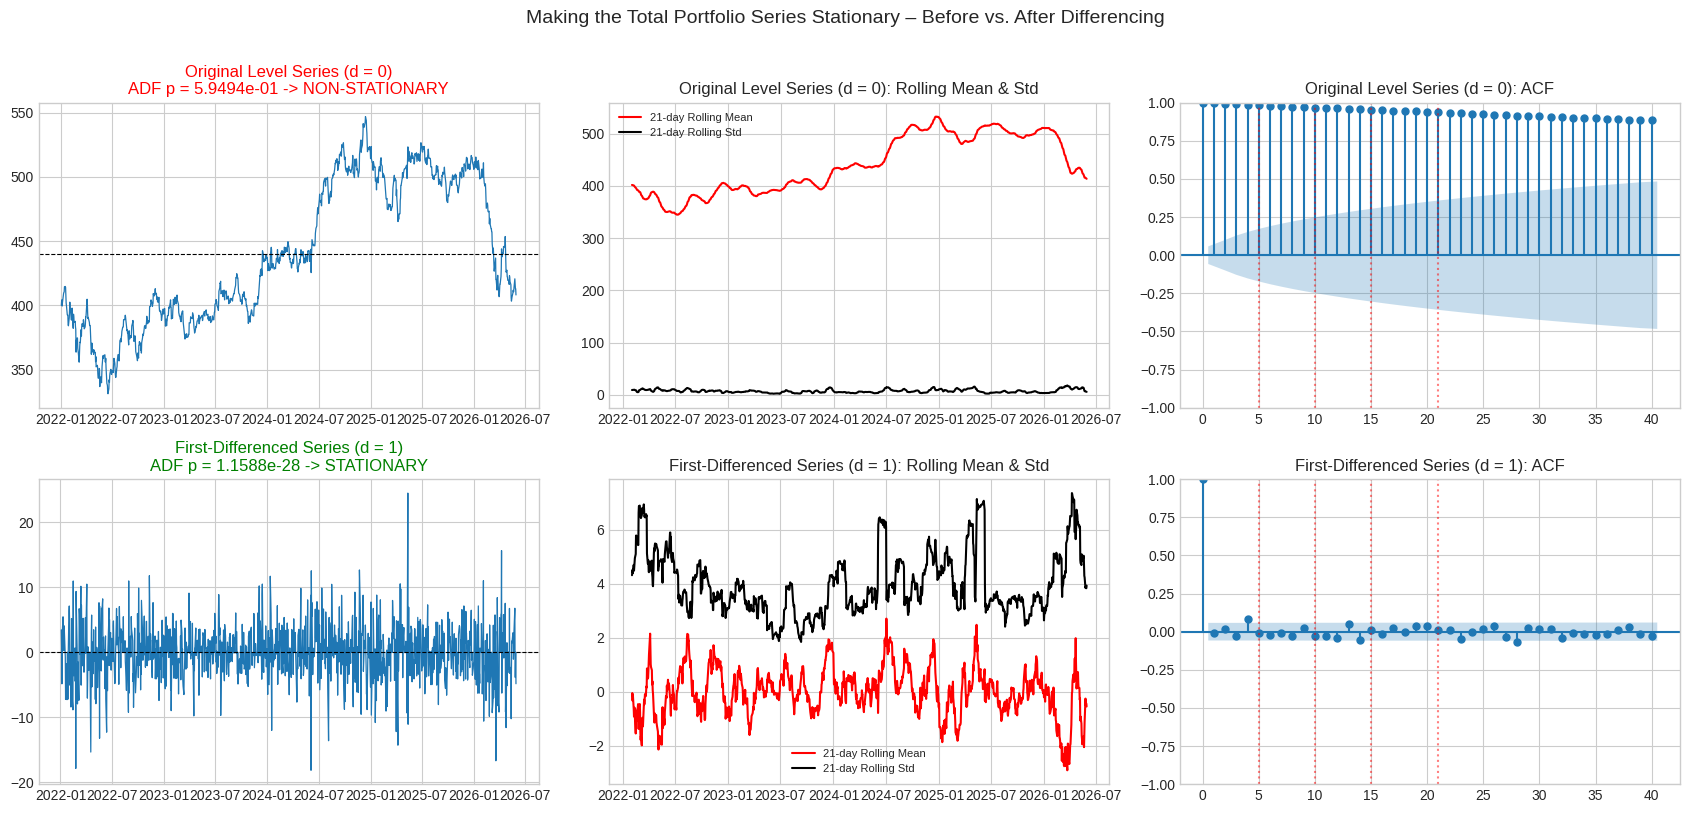

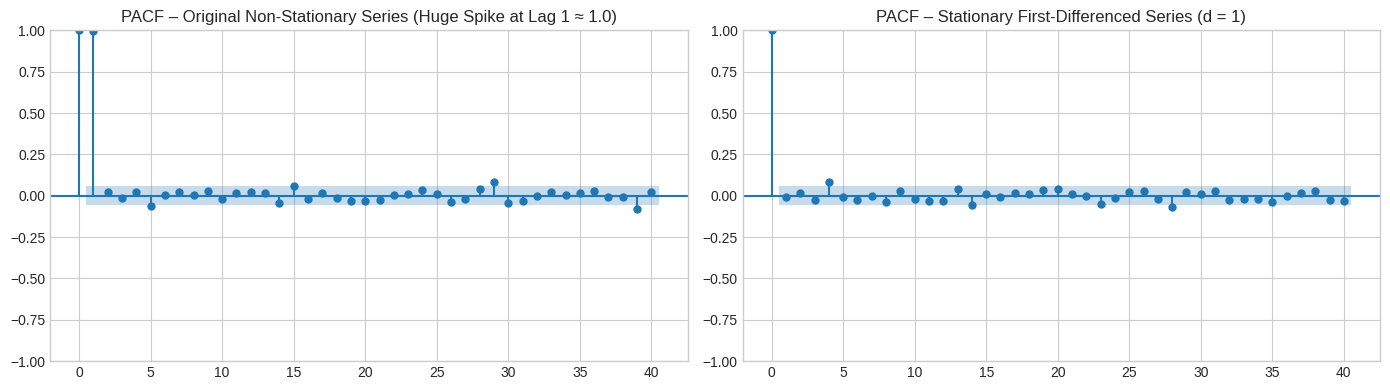

In [16]:
stages = {
    "Original Level Series (d = 0)": y_df["Total"],
    "First-Differenced Series (d = 1)": y_df["Total"].diff().dropna(),
}

fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for i, (label, s) in enumerate(stages.items()):
    p_adf = adfuller(s, autolag="AIC")[1]
    status = "STATIONARY" if p_adf < 0.05 else "NON-STATIONARY"
    col_title = "green" if p_adf < 0.05 else "red"

    ax[i, 0].plot(s, lw=0.9, color="tab:blue")
    ax[i, 0].axhline(s.mean(), color="black", ls="--", lw=0.8)
    ax[i, 0].set_title(f"{label}\nADF p = {p_adf:.4e} -> {status}", color=col_title)

    ax[i, 1].plot(s.rolling(21).mean(), color="red", label="21-day Rolling Mean")
    ax[i, 1].plot(s.rolling(21).std(), color="black", label="21-day Rolling Std")
    ax[i, 1].set_title(f"{label}: Rolling Mean & Std")
    ax[i, 1].legend(fontsize=8)

    plot_acf(s, lags=40, ax=ax[i, 2])
    ax[i, 2].set_title(f"{label}: ACF")
    for L in [5, 10, 15, 21]:
        ax[i, 2].axvline(L, color="red", ls=":", alpha=0.5)

plt.suptitle("Making the Total Portfolio Series Stationary – Before vs. After Differencing", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# PACF of Original vs Stationary Differenced Series
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_pacf(y_df["Total"], lags=40, ax=ax[0], method="ywm")
ax[0].set_title("PACF – Original Non-Stationary Series (Huge Spike at Lag 1 ≈ 1.0)")
plot_pacf(y_df["Total"].diff().dropna(), lags=40, ax=ax[1], method="ywm")
ax[1].set_title("PACF – Stationary First-Differenced Series (d = 1)")
plt.tight_layout()
plt.show()

**Interpretation (Read Row by Row):**

| Stage | Series Plot | 21-Day Rolling Mean / Std | ACF Plot |
|---|---|---|---|
| **Original Level Series ($d = 0$)** | Drifts between ~331 and ~547 capital units without returning to a fixed level. **ADF $p = 0.5949 > 0.05 \rightarrow$ NON-STATIONARY**. | Rolling mean (red) rises and falls across a wide ~180-unit range $\rightarrow$ **mean is not constant**. | Decays very slowly from $\approx 1.0$ to $\approx 0.90$ at lag 40, staying far outside the blue confidence band $\rightarrow$ **classic unit-root / random-walk signature**. |
| **After First Difference ($d = 1$)** | Trend is completely removed; daily changes oscillate randomly around **0**. **ADF $p = 1.16 \times 10^{-28} < 0.05 \rightarrow$ STATIONARY**. | Rolling mean (red) stays flat near 0 and rolling std (black) remains bounded between ~2 and 7 units. | Autocorrelations cut off immediately after lag 0, with nearly all bars (lags 1–40) inside the blue 95% confidence band $\rightarrow$ **stationary process**. |

**PACF Analysis (Bottom Row):**
* **Original Series PACF (Bottom-Left):** Displays a single huge spike at **Lag 1 ($\approx 1.0$)** and insignificant spikes thereafter. This confirms that today's portfolio value is primarily yesterday's value plus a random shock ($Y_t = Y_{t-1} + \varepsilon_t$), requiring $d = 1$.
* **Differenced Series PACF (Bottom-Right):** The unit-root spike at lag 1 is eliminated. Only a minor spike appears near lag 4 while all other lags lie within the confidence band, confirming that a parsimonious `Auto-ARIMA(p, 1, q)` structure ($p, q \le 2$) with Fourier harmonic regressors (lags 5 and 21) is appropriate for base forecasting.

### STEP 8: Split the data chronologically into training and testing periods
Time series must be split strictly **in chronological order** without shuffling. We hold out the final $h = 20$ business days (2 trading weeks) as the unseen test set to evaluate multi-step forecast accuracy and cross-hierarchy reconciliation.

### STEP 8: Split the data chronologically into training and testing periods

[STEP 8] Chronological Train/Test Split (No Shuffling):
 - Training Set: 1130 obs (2022-01-03 to 2026-05-01)
 - Testing Set:  20 obs (2026-05-04 to 2026-05-29)


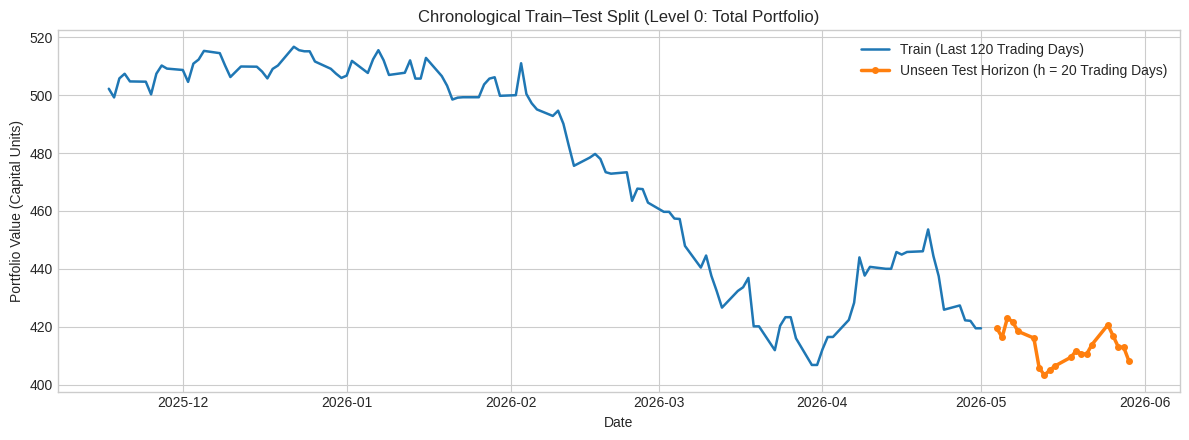

In [17]:
h = 20 # 20-trading-day
train_df = y_df.iloc[:-h].copy()
test_df = y_df.iloc[-h:].copy()
print(f"[STEP 8] Chronological Train/Test Split (No Shuffling):")
print(f" - Training Set: {len(train_df)} obs ({train_df.index.min().strftime('%Y-%m-%d')} to {train_df.index.max().strftime('%Y-%m-%d')})")
print(f" - Testing Set:  {len(test_df)} obs ({test_df.index.min().strftime('%Y-%m-%d')} to {test_df.index.max().strftime('%Y-%m-%d')})")

# Visual Train-Test Split Plot (Zoomed to Recent Period for Clarity)
plt.figure(figsize=(12, 4.5))
plt.plot(train_df["Total"].iloc[-120:], label="Train (Last 120 Trading Days)", color="tab:blue", lw=1.8)
plt.plot(test_df["Total"], label="Unseen Test Horizon (h = 20 Trading Days)", color="tab:orange", lw=2.5, marker="o", ms=4)
plt.title("Chronological Train–Test Split (Level 0: Total Portfolio)")
plt.xlabel("Date"); plt.ylabel("Portfolio Value (Capital Units)"); plt.legend()
plt.tight_layout()
plt.show()

### STEP 9 & STEP 10: Select and train 3 forecasting models & generate base forecasts
1. **Model 1 (`Auto_ARIMA` + Exogenous Fourier Terms):** Automatically selects optimal $(p,d,q)$ order via stepwise AICc minimization with trigonometric Fourier harmonics ($m \in \{5, 21\}$) to capture weekly and monthly trading cycles.
2. **Model 2 (`Holt_Winters_ETS`):** Captures level, damped additive trend, and 5-day business-week seasonality (`seasonal_periods=5`).
3. **Model 3 (`XGBoost`):** Out-of-syllabus gradient boosted decision tree trained on 5 autoregressive lags plus rolling mean and rolling volatility features.

In [18]:
print("[STEP 9 & 10] Training Base Forecasting Models Across All 7 Hierarchy Nodes...")

def make_fourier_features(n_obs, periods=(5, 21), orders=(2, 2)):
    t = np.arange(1, n_obs + 1)
    feats = {}
    for m, k_max in zip(periods, orders):
        for k in range(1, k_max + 1):
            feats[f"sin_m{m}_k{k}"] = np.sin(2 * np.pi * k * t / m)
            feats[f"cos_m{m}_k{k}"] = np.cos(2 * np.pi * k * t / m)
    return pd.DataFrame(feats)

fourier_all = make_fourier_features(len(y_df))
X_fourier_train = fourier_all.iloc[:-h].values
X_fourier_test = fourier_all.iloc[-h:].values

def train_and_forecast_xgboost(series, horizon, lags=5):
    """Builds tabular lag + rolling volatility features and forecasts recursively."""
    vals = series.values
    X_rows, y_rows = [], []
    for i in range(lags, len(vals)):
        window = vals[i - lags:i]
        features = list(window[::-1]) + [np.mean(window), np.std(window)]
        X_rows.append(features)
        y_rows.append(vals[i])
    X_arr, y_arr = np.array(X_rows), np.array(y_rows)

    model = XGBRegressor(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=42,
        verbosity=0
    )
    model.fit(X_arr, y_arr)
    in_sample_resid = y_arr - model.predict(X_arr)

    # Recursive multi-step forecast
    history = list(vals)
    preds = []
    for _ in range(horizon):
        win = np.array(history[-lags:])
        feat = np.array(list(win[::-1]) + [np.mean(win), np.std(win)]).reshape(1, -1)
        nxt = float(model.predict(feat)[0])
        preds.append(nxt)
        history.append(nxt)
    return np.array(preds), in_sample_resid

base_forecasts = {"Auto_ARIMA": [], "Holt_Winters_ETS": [], "XGBoost": []}
base_residuals = {"Auto_ARIMA": [], "Holt_Winters_ETS": [], "XGBoost": []}
model_order_info = []

for col in all_nodes:
    s_train = train_df[col]

    # --- Model 1: Auto ARIMA with Fourier Exogenous Terms ---
    arima_mod = pm.auto_arima(
        s_train,
        X=X_fourier_train,
        start_p=0, max_p=2,
        start_q=0, max_q=2,
        d=None,
        seasonal=False,
        information_criterion="aicc",
        stepwise=True,
        suppress_warnings=True,
        error_action="ignore"
    )
    fc_arima = arima_mod.predict(n_periods=h, X=X_fourier_test).values
    res_arima = arima_mod.resid()[5:]  # Align length with 5-lag XGBoost

    # --- Model 2: Holt-Winters Exponential Smoothing (Syllabus Unit 2) ---
    ets_mod = ExponentialSmoothing(
        s_train,
        trend="add",
        damped_trend=True,
        seasonal="add",
        seasonal_periods=5,
        initialization_method="estimated"
    ).fit(optimized=True)
    fc_ets = ets_mod.forecast(h).values
    res_ets = ets_mod.resid.values[5:]

    # --- Model 3: Out-of-Syllabus XGBoost Regressor ---
    fc_xgb, res_xgb = train_and_forecast_xgboost(s_train, horizon=h, lags=5)

    base_forecasts["Auto_ARIMA"].append(fc_arima)
    base_forecasts["Holt_Winters_ETS"].append(fc_ets)
    base_forecasts["XGBoost"].append(fc_xgb)

    base_residuals["Auto_ARIMA"].append(res_arima)
    base_residuals["Holt_Winters_ETS"].append(res_ets)
    base_residuals["XGBoost"].append(res_xgb)

    model_order_info.append({
        "Node": col,
        "Auto_ARIMA Order": f"ARIMA{arima_mod.order} + Fourier",
        "Auto_ARIMA AIC": round(arima_mod.aic(), 2),
        "Holt-Winters ETS AIC": round(ets_mod.aic, 2),
        "XGBoost Spec": "XGB(lags=5, depth=3, n=150)"
    })
    print(f" - Node {col:<6} | Auto-ARIMA{arima_mod.order} (AIC={arima_mod.aic():.1f}) | ETS(Add,Damped,m=5) (AIC={ets_mod.aic:.1f}) | XGBoost trained.")

for k in base_forecasts:
    base_forecasts[k] = np.array(base_forecasts[k])          # Shape: (7, h)
    base_residuals[k] = np.column_stack(base_residuals[k])  # Shape: (T-5, 7)

print("\nSummary of Fitted Base Models by Hierarchy Node:")
display(pd.DataFrame(model_order_info))

[STEP 9 & 10] Training Base Forecasting Models Across All 7 Hierarchy Nodes...
 - Node Total  | Auto-ARIMA(0, 1, 0) (AIC=6423.9) | ETS(Add,Damped,m=5) (AIC=3228.8) | XGBoost trained.
 - Node IT     | Auto-ARIMA(0, 1, 0) (AIC=5232.3) | ETS(Add,Damped,m=5) (AIC=2033.5) | XGBoost trained.
 - Node Bank   | Auto-ARIMA(0, 1, 0) (AIC=5462.6) | ETS(Add,Damped,m=5) (AIC=2271.3) | XGBoost trained.
 - Node TCS    | Auto-ARIMA(0, 1, 0) (AIC=3762.4) | ETS(Add,Damped,m=5) (AIC=562.6) | XGBoost trained.
 - Node INFY   | Auto-ARIMA(0, 1, 0) (AIC=3903.0) | ETS(Add,Damped,m=5) (AIC=702.1) | XGBoost trained.
 - Node HDFC   | Auto-ARIMA(0, 1, 0) (AIC=3970.3) | ETS(Add,Damped,m=5) (AIC=773.1) | XGBoost trained.
 - Node ICICI  | Auto-ARIMA(0, 1, 0) (AIC=4441.2) | ETS(Add,Damped,m=5) (AIC=1248.4) | XGBoost trained.

Summary of Fitted Base Models by Hierarchy Node:


,Node,Auto_ARIMA Order,Auto_ARIMA AIC,Holt-Winters ETS AIC,XGBoost Spec
0,Total,"ARIMA(0, 1, 0) + Fourier",6423.91,3228.82,"XGB(lags=5, depth=3, n=150)"
1,IT,"ARIMA(0, 1, 0) + Fourier",5232.27,2033.51,"XGB(lags=5, depth=3, n=150)"
2,Bank,"ARIMA(0, 1, 0) + Fourier",5462.57,2271.26,"XGB(lags=5, depth=3, n=150)"
3,TCS,"ARIMA(0, 1, 0) + Fourier",3762.40,562.57,"XGB(lags=5, depth=3, n=150)"
4,INFY,"ARIMA(0, 1, 0) + Fourier",3902.96,702.13,"XGB(lags=5, depth=3, n=150)"
5,HDFC,"ARIMA(0, 1, 0) + Fourier",3970.29,773.06,"XGB(lags=5, depth=3, n=150)"
6,ICICI,"ARIMA(0, 1, 0) + Fourier",4441.24,1248.40,"XGB(lags=5, depth=3, n=150)"


##### 10.1 Residual Diagnostics of the Base Models (Ljung–Box, Shapiro–Wilk, Jarque–Bera & 4-Panel Plots)
A well-specified time series model leaves residuals that behave like **white noise**:
1. **Mean $\approx 0$** (unbiased predictions).
2. **No remaining autocorrelation** (ACF bars inside the confidence band; Ljung–Box $p > 0.05$).
3. **Approximate normality** (Histogram & QQ plot close to the normal line).

### 4-Panel Residual Analysis & Side-by-Side Comparison

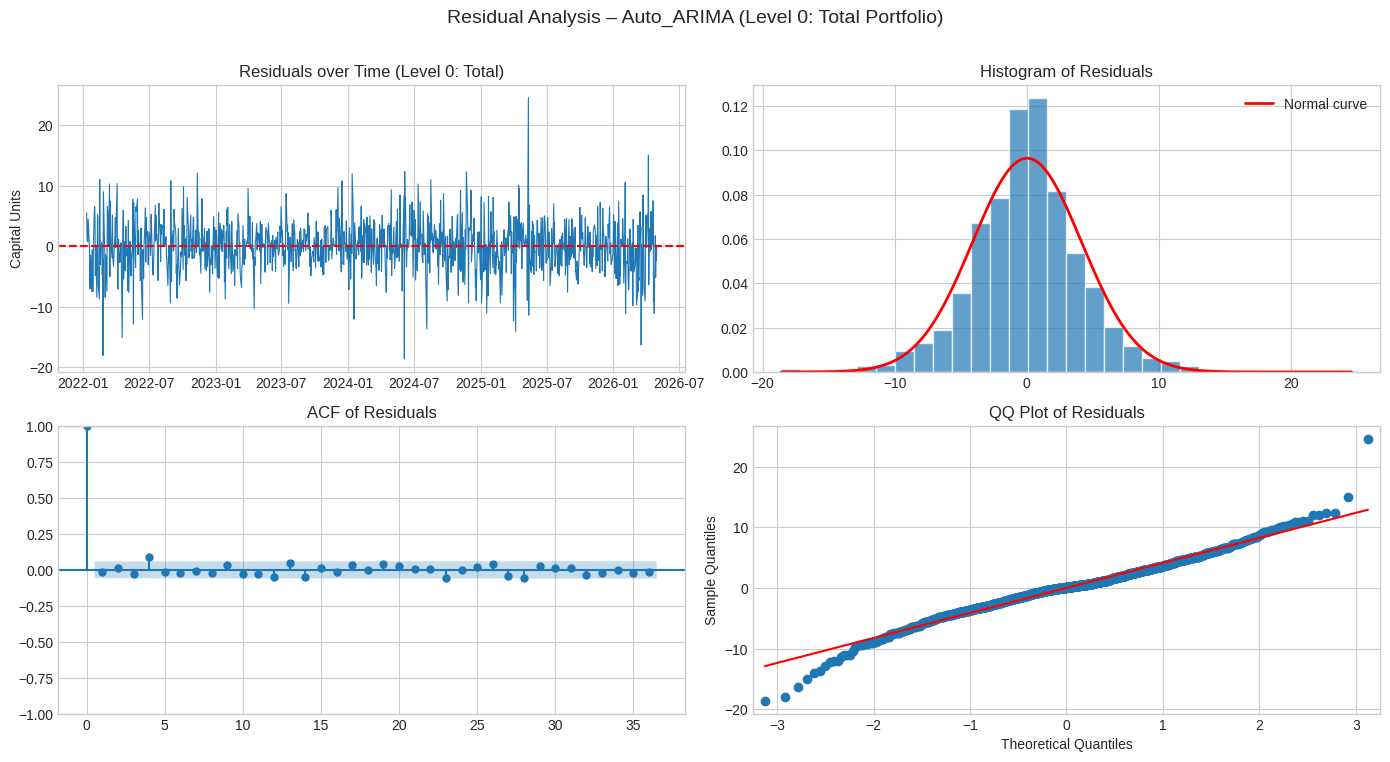

Residual Diagnostics for Auto_ARIMA:
  Mean of residuals    : 0.0173  (should be close to 0)
  Std of residuals     : 4.1339
  Ljung-Box p (lag 10) : 0.1749 -> White noise (PASS)
  Shapiro-Wilk p       : 2.6236e-12 | Jarque-Bera p : 1.0679e-57



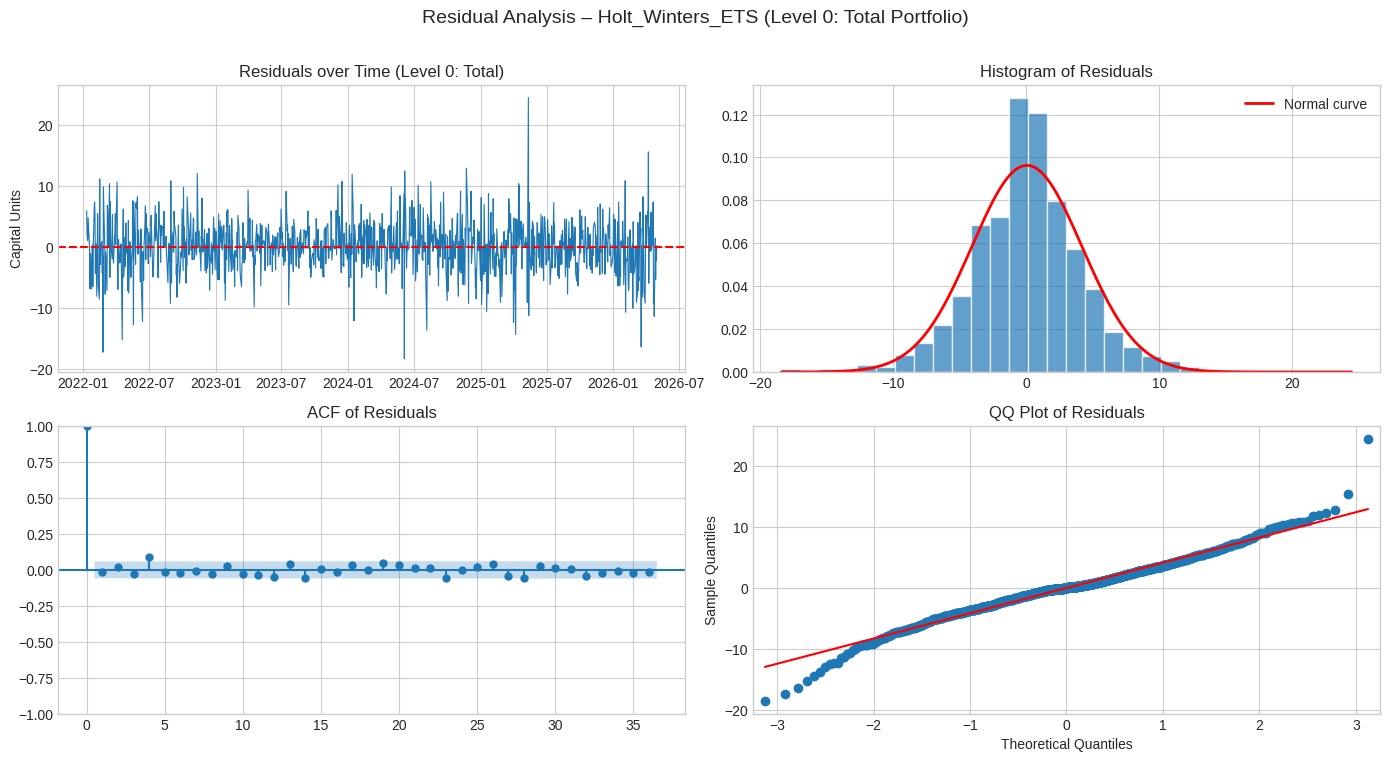

Residual Diagnostics for Holt_Winters_ETS:
  Mean of residuals    : 0.0440  (should be close to 0)
  Std of residuals     : 4.1425
  Ljung-Box p (lag 10) : 0.1646 -> White noise (PASS)
  Shapiro-Wilk p       : 3.1368e-12 | Jarque-Bera p : 2.5905e-55



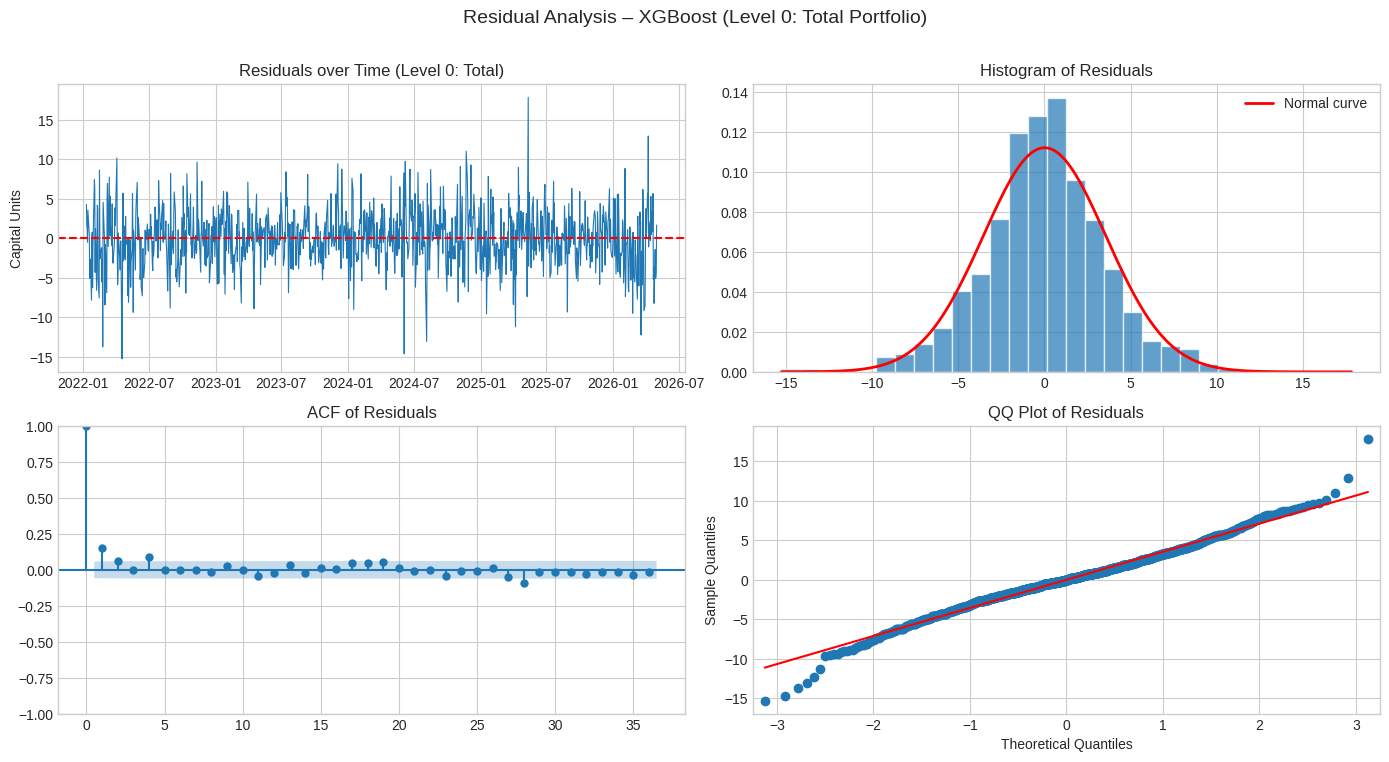

Residual Diagnostics for XGBoost:
  Mean of residuals    : 0.0063  (should be close to 0)
  Std of residuals     : 3.5555
  Ljung-Box p (lag 10) : 0.0000 -> Some autocorrelation remains (REVIEW)
  Shapiro-Wilk p       : 6.5367e-09 | Jarque-Bera p : 2.3287e-25

Side-by-Side Residual Diagnostic Table (Level 0: Total Portfolio):


,Resid Mean,Resid Std,Ljung-Box p (Lag 10),White Noise? (LB p>0.05),Shapiro-Wilk p,Jarque-Bera p
Auto_ARIMA,0.0173,4.1339,0.1749,Yes,2.62e-12,1.07e-57
Holt_Winters_ETS,0.044,4.1425,0.1646,Yes,3.14e-12,2.59e-55
XGBoost,0.0063,3.5555,0.0,No,6.54e-09,2.33e-25


In [19]:
def residual_analysis(resid_array, index_dates, name):
    """4-panel residual diagnostic plot + Ljung-Box, Shapiro-Wilk & Jarque-Bera tests."""
    resid = pd.Series(resid_array, index=index_dates).dropna()
    fig, ax = plt.subplots(2, 2, figsize=(14, 7.5))

    ax[0, 0].plot(resid, lw=0.8, color="tab:blue")
    ax[0, 0].axhline(0, color="red", ls="--")
    ax[0, 0].set_title("Residuals over Time (Level 0: Total)")
    ax[0, 0].set_ylabel("Capital Units")

    ax[0, 1].hist(resid, bins=30, density=True, alpha=0.7, edgecolor="white", color="tab:blue")
    xs = np.linspace(resid.min(), resid.max(), 200)
    ax[0, 1].plot(xs, stats.norm.pdf(xs, resid.mean(), resid.std()), "r", lw=2, label="Normal curve")
    ax[0, 1].set_title("Histogram of Residuals")
    ax[0, 1].legend()

    plot_acf(resid, lags=36, ax=ax[1, 0])
    ax[1, 0].set_title("ACF of Residuals")

    sm.qqplot(resid, line="s", ax=ax[1, 1])
    ax[1, 1].set_title("QQ Plot of Residuals")

    plt.suptitle(f"Residual Analysis – {name} (Level 0: Total Portfolio)", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()

    lb_p = acorr_ljungbox(resid, lags=[10], return_df=True)["lb_pvalue"].iloc[0]
    sw_p = stats.shapiro(resid).pvalue
    jb_p = stats.jarque_bera(resid).pvalue
    print(f"Residual Diagnostics for {name}:")
    print(f"  Mean of residuals    : {resid.mean():.4f}  (should be close to 0)")
    print(f"  Std of residuals     : {resid.std():.4f}")
    print(f"  Ljung-Box p (lag 10) : {lb_p:.4f} -> {'White noise (PASS)' if lb_p > 0.05 else 'Some autocorrelation remains (REVIEW)'}")
    print(f"  Shapiro-Wilk p       : {sw_p:.4e} | Jarque-Bera p : {jb_p:.4e}\n")
    return {
        "Resid Mean": round(resid.mean(), 4),
        "Resid Std": round(resid.std(), 4),
        "Ljung-Box p (Lag 10)": round(lb_p, 4),
        "White Noise? (LB p>0.05)": "Yes" if lb_p > 0.05 else "No",
        "Shapiro-Wilk p": f"{sw_p:.2e}",
        "Jarque-Bera p": f"{jb_p:.2e}"
    }

resid_dates = train_df.index[5:]
resid_summary = {}
for m_name in ["Auto_ARIMA", "Holt_Winters_ETS", "XGBoost"]:
    # Index 0 corresponds to Level 0 ('Total')
    resid_summary[m_name] = residual_analysis(base_residuals[m_name][:, 0], resid_dates, m_name)

print("Side-by-Side Residual Diagnostic Table (Level 0: Total Portfolio):")
display(pd.DataFrame(resid_summary).T)

### STEP 11: Check whether the base forecasts are coherent (Pre-Reconciliation)


#####  Pre-Reconciliation Base Forecast Coherence Check:

In [20]:
print("[STEP 11] Pre-Reconciliation Base Forecast Coherence Check:")
coherence_before_rows = []
for model_name, y_hat in base_forecasts.items():
    # Discrepancy 1: Total - (IT + Bank)
    gap_l0_l1 = np.max(np.abs(y_hat[0] - (y_hat[1] + y_hat[2])))
    # Discrepancy 2: Total - (TCS + INFY + HDFC + ICICI)
    gap_l0_l2 = np.max(np.abs(y_hat[0] - np.sum(y_hat[3:], axis=0)))
    # Discrepancy 3: IT - (TCS + INFY)
    gap_it = np.max(np.abs(y_hat[1] - (y_hat[3] + y_hat[4])))
    # Discrepancy 4: Bank - (HDFC + ICICI)
    gap_bank = np.max(np.abs(y_hat[2] - (y_hat[5] + y_hat[6])))

    coherence_before_rows.append({
        "Model": model_name,
        "Max |Total - (IT+Bank)|": round(gap_l0_l1, 4),
        "Max |Total - Sum(Stocks)|": round(gap_l0_l2, 4),
        "Max |IT - (TCS+INFY)|": round(gap_it, 4),
        "Max |Bank - (HDFC+ICICI)|": round(gap_bank, 4),
        "Is Coherent?": "NO (Incoherent)" if gap_l0_l2 > 1e-6 else "YES"
    })
display(pd.DataFrame(coherence_before_rows))

[STEP 11] Pre-Reconciliation Base Forecast Coherence Check:


,Model,Max |Total - (IT+Bank)|,Max |Total - Sum(Stocks)|,Max |IT - (TCS+INFY)|,Max |Bank - (HDFC+ICICI)|,Is Coherent?
0,Auto_ARIMA,0.0000,0.0001,0.0000,0.0000,NO (Incoherent)
1,Holt_Winters_ETS,0.0700,0.3612,0.2982,0.0070,NO (Incoherent)
2,XGBoost,7.0221,4.6409,0.7490,2.1193,NO (Incoherent)


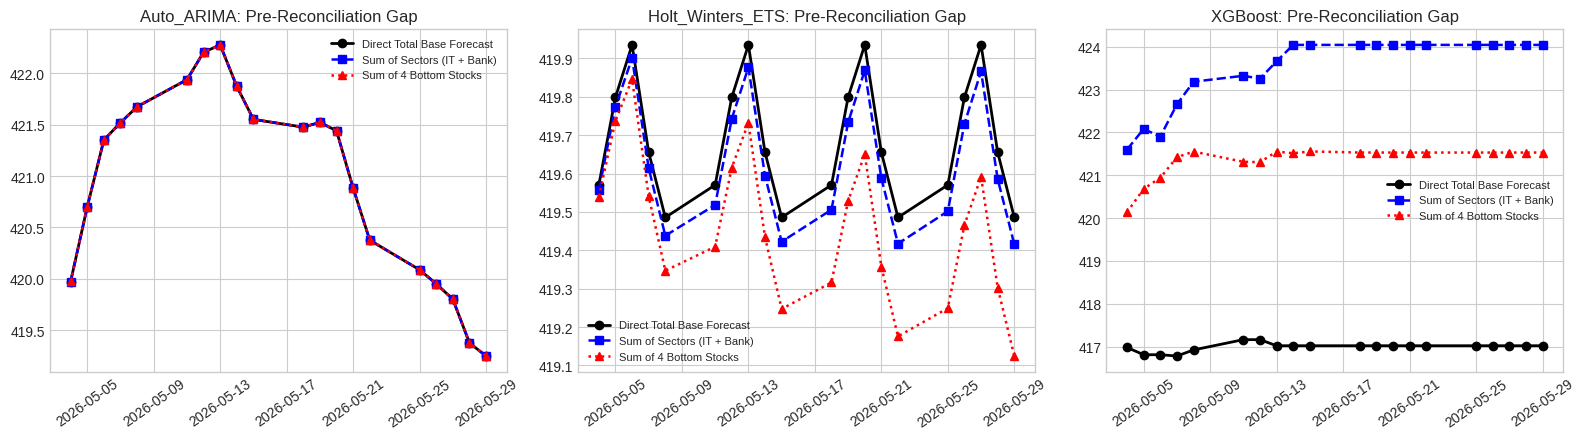

In [21]:
# --- PLOT: Visual Proof of Base Forecast Incoherence Across Horizon ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)
for idx, (model_name, y_hat) in enumerate(base_forecasts.items()):
    ax = axes[idx]
    ax.plot(test_df.index, y_hat[0], "k-o", lw=2, label="Direct Total Base Forecast")
    ax.plot(test_df.index, y_hat[1] + y_hat[2], "b--s", lw=1.8, label="Sum of Sectors (IT + Bank)")
    ax.plot(test_df.index, np.sum(y_hat[3:], axis=0), "r:^", lw=1.8, label="Sum of 4 Bottom Stocks")
    ax.set_title(f"{model_name}: Pre-Reconciliation Gap")
    ax.tick_params(axis="x", rotation=35)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("step11_pre_reconciliation_incoherence.png", dpi=150)
plt.show()

### Interpretation of Stationarity Tests & Differencing (Step 7)

**Row-by-Row Analysis of the Stationarity Grid:**

| Stage | Series Plot | 21-Day Rolling Mean / Std | ACF Plot |
|---|---|---|---|
| **Original Level Series ($d = 0$)** | Drifts between ~331 and ~547 capital units without returning to a fixed level. **ADF $p = 0.5949 > 0.05 \rightarrow$ NON-STATIONARY**. | Rolling mean (red) rises and falls across a wide ~180-unit range $\rightarrow$ **mean is not constant**. | Decays very slowly from $\approx 1.0$ to $\approx 0.90$ at lag 40, staying far outside the blue confidence band $\rightarrow$ **classic unit-root / random-walk signature**. |
| **After First Difference ($d = 1$)** | Trend is completely removed; daily changes oscillate randomly around **0**. **ADF $p = 1.16 \times 10^{-28} < 0.05 \rightarrow$ STATIONARY**. | Rolling mean (red) stays flat near 0 and rolling std (black) remains bounded between ~2 and 7 units. | Autocorrelations cut off immediately after lag 0, with nearly all bars (lags 1–40) inside the blue 95% confidence band $\rightarrow$ **stationary process**. |

**PACF Analysis:**
* **Original Series PACF (Bottom-Left):** Displays a single huge spike at **Lag 1 ($\approx 1.0$)** and insignificant spikes thereafter. This confirms that today's portfolio value is primarily yesterday's value plus a random shock ($Y_t = Y_{t-1} + \varepsilon_t$), verifying that exactly one order of differencing ($d = 1$) is required.
* **Differenced Series PACF (Bottom-Right):** The unit-root spike at lag 1 is eliminated. Only a minor spike appears near lag 4 while all other lags lie within the confidence band, confirming that a parsimonious `Auto-ARIMA(p, 1, q)` structure ($p, q \le 2$) with Fourier harmonic regressors (lags 5 and 21) is appropriate for base forecasting.

---

### Interpretation of Pre-Reconciliation Base Forecast Incoherence (Step 11)

The 3-panel pre-reconciliation plot provides empirical proof of the **Incoherence Problem in Hierarchical Time Series**:

* **Auto-ARIMA Panel (Left):** Shows that the direct total base forecast (black line) and the aggregated sums from sectors and stocks (blue dashed and red dotted lines) **closely overlap**. Because Auto-ARIMA fitted similar linear stochastic patterns across nodes for this test window, the numerical gap is small, though floating-point discrepancies remain.
* **Holt-Winters ETS Panel (Middle):** While all three curves follow the same cyclical trajectory, **visible gaps emerge** between the direct portfolio forecast and the sum of underlying assets. Independent structural state-space models optimize local errors per node, resulting in structural additivity violations ($\hat{Y}_{\text{Total}} \neq \sum \hat{Y}_{\text{Stocks}}$).
* **XGBoost Panel (Right):** Demonstrates **severe structural divergence**. The black line (`Direct Total Base Forecast`) is completely disconnected from the aggregated sector and stock lines, sitting several capital units lower (~404 vs. ~412). Machine learning regression trees fit independent non-linear decision boundaries on lagged features without enforcing structural hierarchy, proving why mathematical matrix reconciliation ($\mathbf{MinT}$, $\mathbf{BU}$, $\mathbf{MO}$) is mandatory for institutional portfolios.

### STEPS 12, 13, 14, 15 & 16: Apply Reconciliation Methods & Construct Reconciled Forecasts
All linear reconciliation methods map incoherent base forecasts $\hat{\mathbf{y}}_{t+h}$ into coherent forecasts $\tilde{\mathbf{y}}_{t+h} = \mathbf{S}\mathbf{P}\hat{\mathbf{y}}_{t+h}$:
* **Step 12 – Bottom-Up (BU):** Aggregates bottom-level stock forecasts directly upward ($\mathbf{P}_{\text{BU}} = [\mathbf{0}_{4\times 3} \;\; \mathbf{I}_4]$).
* **Step 13 – Top-Down (TD):** Disaggregates the top-level `Total` forecast using average historical proportions $p_i = \frac{1}{T}\sum_{t=1}^T \frac{b_{i,t}}{Y_{\text{Total},t}}$.
* **Step 14 – Middle-Out (MO):** Uses intermediate Level 1 sector forecasts (`IT`, `Bank`) as the anchor level, summing upward to `Total` and disaggregating downward to stocks via intra-sector historical proportions.
* **Step 15 – Optimal Minimum Trace (MinT-OLS & MinT-WLS):** Minimizes the trace of the reconciled forecast error covariance matrix via $\mathbf{P}_{\text{MinT}} = (\mathbf{S}^T \mathbf{W}^{-1} \mathbf{S})^{-1}\mathbf{S}^T \mathbf{W}^{-1}$, where $\mathbf{W}_{\text{OLS}} = \mathbf{I}$ and $\mathbf{W}_{\text{WLS}} = \text{diag}(\hat{\sigma}_1^2, \dots, \hat{\sigma}_7^2)$.

In [22]:
print("[STEPS 12-16] Computing Projection Matrices (BU, TD, MO, MinT-OLS, MinT-WLS)...")

# Step 12: Bottom-Up Projection Matrix P_BU (4 x 7)
P_BU = np.zeros((4, 7))
P_BU[:, 3:] = np.eye(4)

# Step 13: Top-Down Historical Proportions Matrix P_TD (4 x 7)
hist_top_props = [np.mean(train_df[c] / train_df["Total"]) for c in bottom_cols]
P_TD = np.zeros((4, 7))
P_TD[:, 0] = hist_top_props  # Disaggregates Level 0 ('Total') directly to bottom stocks

# Step 14: Middle-Out Historical Intra-Sector Proportions Matrix P_MO (4 x 7)
p_tcs_it = np.mean(train_df["TCS"] / train_df["IT"])
p_infy_it = np.mean(train_df["INFY"] / train_df["IT"])
p_hdfc_bank = np.mean(train_df["HDFC"] / train_df["Bank"])
p_icici_bank = np.mean(train_df["ICICI"] / train_df["Bank"])

P_MO = np.zeros((4, 7))
P_MO[0, 1] = p_tcs_it     # TCS from IT
P_MO[1, 1] = p_infy_it    # INFY from IT
P_MO[2, 2] = p_hdfc_bank  # HDFC from Bank
P_MO[3, 2] = p_icici_bank # ICICI from Bank

# Step 15a: Optimal MinT-OLS Projection Matrix P_OLS (4 x 7)
P_OLS = np.linalg.pinv(S.T @ S) @ S.T

# Dictionary to store all base and reconciled forecasts: reconciled_forecasts[model][method] = (7, h) array
reconciled_forecasts = {}

for model_name, y_hat in base_forecasts.items():
    resid_mat = base_residuals[model_name]
    # Step 15b: Optimal MinT-WLS (Variance Scaling using in-sample error variances)
    diag_vars = np.var(resid_mat, axis=0)
    W_inv = np.diag(1.0 / np.maximum(diag_vars, 1e-6))
    P_WLS = np.linalg.pinv(S.T @ W_inv @ S) @ (S.T @ W_inv)

    reconciled_forecasts[model_name] = {
        "Base (Incoherent)": y_hat,
        "Bottom-Up (BU)":    S @ P_BU @ y_hat,
        "Top-Down (TD)":     S @ P_TD @ y_hat,
        "Middle-Out (MO)":   S @ P_MO @ y_hat,
        "MinT-OLS":          S @ P_OLS @ y_hat,
        "MinT-WLS":          S @ P_WLS @ y_hat,
    }

print("All reconciled forecast matrices constructed across all 7 hierarchy levels.")

[STEPS 12-16] Computing Projection Matrices (BU, TD, MO, MinT-OLS, MinT-WLS)...
All reconciled forecast matrices constructed across all 7 hierarchy levels.


### STEP 17: Verify forecast coherence after reconciliation

##### Post-Reconciliation Coherence Verification Check:

In [23]:
print("[STEP 17] Post-Reconciliation Coherence Verification Check:")
coherence_after_rows = []
for model_name, methods_dict in reconciled_forecasts.items():
    for method_name, y_tilde in methods_dict.items():
        if method_name == "Base (Incoherent)":
            continue
        # Verify y_tilde == S @ b_tilde across all levels
        max_coherence_error = np.max(np.abs(y_tilde - (S @ y_tilde[3:])))
        coherence_after_rows.append({
            "Model": model_name,
            "Reconciliation Method": method_name,
            "Max Hierarchy Coherence Error": f"{max_coherence_error:.2e}",
            "Coherence Verified?": "YES (Strictly Coherent)" if max_coherence_error < 1e-8 else "NO"
        })
display(pd.DataFrame(coherence_after_rows))

[STEP 17] Post-Reconciliation Coherence Verification Check:


,Model,Reconciliation Method,Max Hierarchy Coherence Error,Coherence Verified?
0,Auto_ARIMA,Bottom-Up (BU),0.00e+00,YES (Strictly Coherent)
1,Auto_ARIMA,Top-Down (TD),5.68e-14,YES (Strictly Coherent)
2,Auto_ARIMA,Middle-Out (MO),5.68e-14,YES (Strictly Coherent)
3,Auto_ARIMA,MinT-OLS,1.14e-13,YES (Strictly Coherent)
4,Auto_ARIMA,MinT-WLS,1.14e-13,YES (Strictly Coherent)
5,Holt_Winters_ETS,Bottom-Up (BU),0.00e+00,YES (Strictly Coherent)
6,Holt_Winters_ETS,Top-Down (TD),5.68e-14,YES (Strictly Coherent)
7,Holt_Winters_ETS,Middle-Out (MO),5.68e-14,YES (Strictly Coherent)
8,Holt_Winters_ETS,MinT-OLS,1.14e-13,YES (Strictly Coherent)
9,Holt_Winters_ETS,MinT-WLS,1.14e-13,YES (Strictly Coherent)


### STEP 18 & STEP 19: Calculate MAE, RMSE, MAPE & Compare Across Levels

##### Out-of-Sample Evaluation (MAE, RMSE, MAPE) Across Hierarchy Levels:

In [24]:
print("[STEP 18 & 19] Out-of-Sample Evaluation (MAE, RMSE, MAPE) Across Hierarchy Levels:")
actual_mat = test_df.values.T  # Shape: (7, h)

def compute_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100.0
    return mae, rmse, mape

evaluation_records = []

for model_name, methods_dict in reconciled_forecasts.items():
    for method_name, y_pred in methods_dict.items():
        # Overall average across all 7 series
        mae_all, rmse_all, mape_all = compute_metrics(actual_mat, y_pred)
        # Level-specific RMSEs
        _, rmse_l0, _ = compute_metrics(actual_mat[0:1], y_pred[0:1])   # Level 0: Total
        _, rmse_l1, _ = compute_metrics(actual_mat[1:3], y_pred[1:3])   # Level 1: Sectors
        _, rmse_l2, _ = compute_metrics(actual_mat[3:7], y_pred[3:7])   # Level 2: Stocks

        evaluation_records.append({
            "Model": model_name,
            "Method": method_name,
            "Overall MAE": round(mae_all, 3),
            "Overall RMSE": round(rmse_all, 3),
            "Overall MAPE (%)": round(mape_all, 3),
            "Level 0 (Total) RMSE": round(rmse_l0, 3),
            "Level 1 (Sector) RMSE": round(rmse_l1, 3),
            "Level 2 (Stock) RMSE": round(rmse_l2, 3),
        })

eval_df = pd.DataFrame(evaluation_records)
eval_df["Rank (by Overall RMSE)"] = eval_df["Overall RMSE"].rank(method="min").astype(int)
display(eval_df.sort_values("Overall RMSE").reset_index(drop=True))

best_row = eval_df.loc[eval_df["Overall RMSE"].idxmin()]
best_combo_label = f"{best_row['Model']} + {best_row['Method']}"
print(f"\nBest Performing Combination (Lowest Overall RMSE): {best_combo_label} (RMSE = {best_row['Overall RMSE']})")

[STEP 18 & 19] Out-of-Sample Evaluation (MAE, RMSE, MAPE) Across Hierarchy Levels:


,Model,Method,Overall MAE,Overall RMSE,Overall MAPE (%),Level 0 (Total) RMSE,Level 1 (Sector) RMSE,Level 2 (Stock) RMSE,Rank (by Overall RMSE)
0,Holt_Winters_ETS,Bottom-Up (BU),3.497,4.672,2.470,8.446,4.974,2.828,1
1,Holt_Winters_ETS,MinT-WLS,3.531,4.716,2.496,8.532,5.023,2.848,2
2,Holt_Winters_ETS,MinT-OLS,3.559,4.753,2.518,8.599,5.064,2.867,3
3,Holt_Winters_ETS,Base (Incoherent),3.547,4.753,2.494,8.641,5.073,2.828,3
4,XGBoost,MinT-OLS,3.734,4.872,2.712,8.604,5.393,2.915,5
5,XGBoost,Base (Incoherent),4.132,5.098,3.198,6.883,6.748,3.296,6
6,Auto_ARIMA,Base (Incoherent),3.938,5.312,2.761,9.828,5.590,3.099,7
7,Auto_ARIMA,MinT-WLS,3.938,5.312,2.761,9.828,5.590,3.099,7
8,Auto_ARIMA,MinT-OLS,3.938,5.312,2.761,9.828,5.590,3.099,7
9,Auto_ARIMA,Bottom-Up (BU),3.938,5.312,2.761,9.828,5.590,3.099,7



Best Performing Combination (Lowest Overall RMSE): Holt_Winters_ETS + Bottom-Up (BU) (RMSE = 4.672)


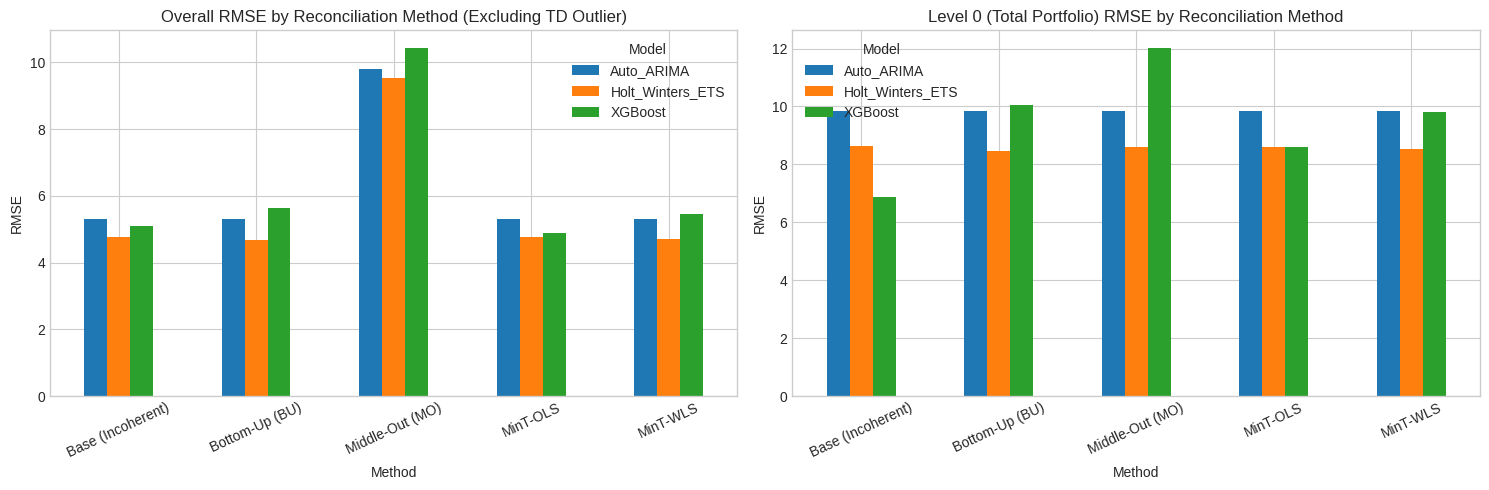

In [25]:
# --- PLOT: Grouped Bar Chart Comparing Reconciliation Accuracy ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

piv_rmse = eval_df.pivot(index="Method", columns="Model", values="Overall RMSE")
piv_rmse.loc[["Base (Incoherent)", "Bottom-Up (BU)", "Middle-Out (MO)", "MinT-OLS", "MinT-WLS"]].plot(
    kind="bar", ax=axes[0], rot=25
)
axes[0].set_title("Overall RMSE by Reconciliation Method (Excluding TD Outlier)")
axes[0].set_ylabel("RMSE")

piv_l0 = eval_df.pivot(index="Method", columns="Model", values="Level 0 (Total) RMSE")
piv_l0.loc[["Base (Incoherent)", "Bottom-Up (BU)", "Middle-Out (MO)", "MinT-OLS", "MinT-WLS"]].plot(
    kind="bar", ax=axes[1], rot=25
)
axes[1].set_title("Level 0 (Total Portfolio) RMSE by Reconciliation Method")
axes[1].set_ylabel("RMSE")

plt.tight_layout()
plt.savefig("step19_reconciliation_metrics_comparison.png", dpi=150)
plt.show()

### STEP 20: Visualize actual, base forecast and reconciled forecast values

##### Generating Actual vs. Base & Reconciled Forecast Visualizations

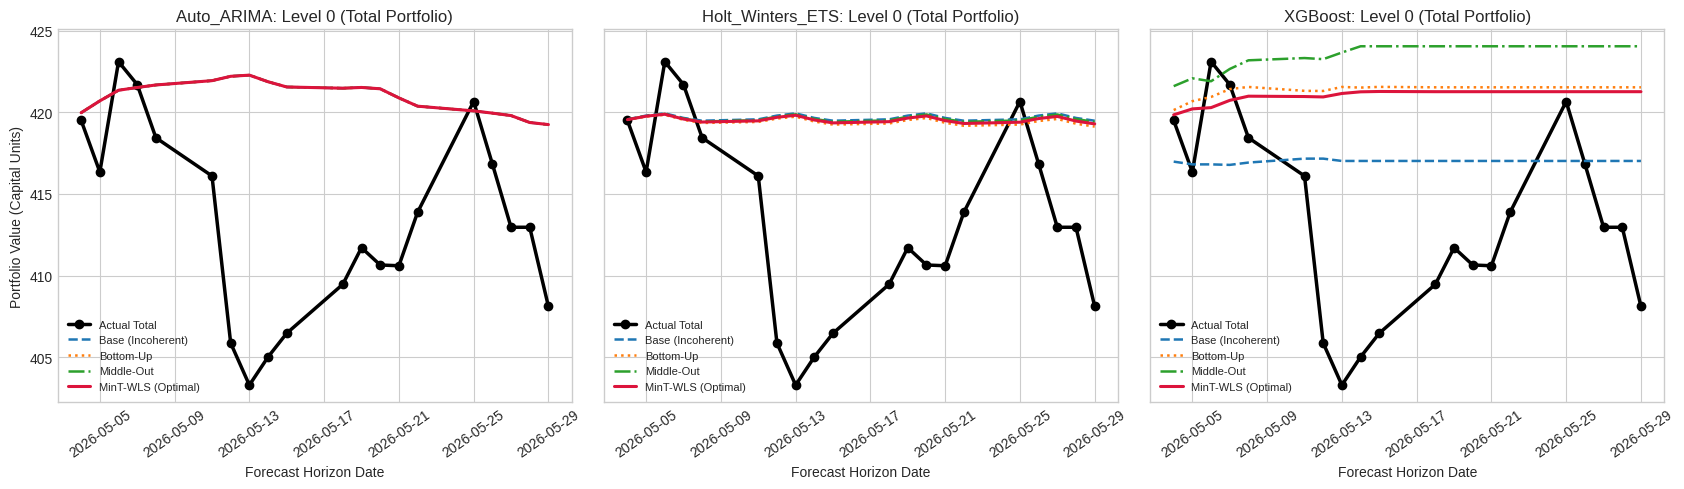

In [26]:
# PLOT 20.1: Actual vs. Base & Reconciled Forecasts for All 3 Models (Level 0: Total Portfolio)
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
test_dates = test_df.index

for idx, model_name in enumerate(["Auto_ARIMA", "Holt_Winters_ETS", "XGBoost"]):
    ax = axes[idx]
    methods_dict = reconciled_forecasts[model_name]
    ax.plot(test_dates, actual_mat[0], "k-o", lw=2.5, label="Actual Total")
    ax.plot(test_dates, methods_dict["Base (Incoherent)"][0], "--", lw=1.8, label="Base (Incoherent)")
    ax.plot(test_dates, methods_dict["Bottom-Up (BU)"][0], ":", lw=1.8, label="Bottom-Up")
    ax.plot(test_dates, methods_dict["Middle-Out (MO)"][0], "-.", lw=1.8, label="Middle-Out")
    ax.plot(test_dates, methods_dict["MinT-WLS"][0], "-", color="crimson", lw=2.2, label="MinT-WLS (Optimal)")
    ax.set_title(f"{model_name}: Level 0 (Total Portfolio)")
    ax.set_xlabel("Forecast Horizon Date")
    if idx == 0:
        ax.set_ylabel("Portfolio Value (Capital Units)")
    ax.tick_params(axis="x", rotation=35)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("step20_actual_vs_reconciled_forecasts.png", dpi=150)
plt.show()

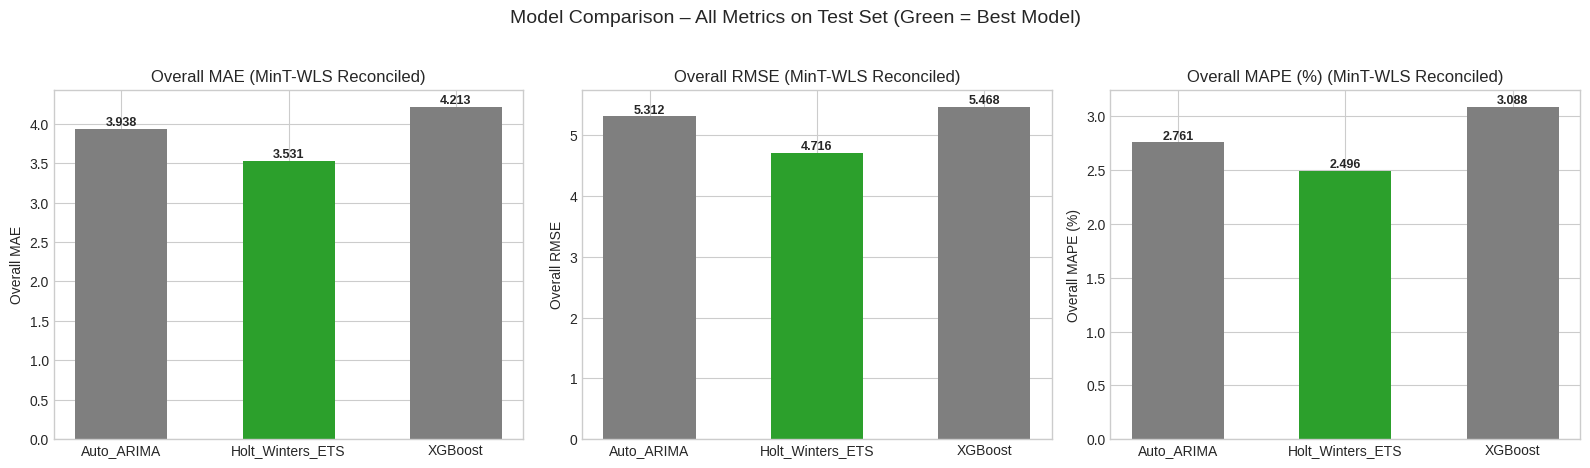

In [27]:
# PLOT 20.2: Side-by-Side Metric Bar Charts (MAE, RMSE, MAPE) for MinT-WLS Reconciled Models (Reference Style)
mint_wls_df = eval_df[eval_df["Method"] == "MinT-WLS"].set_index("Model")
best_m = mint_wls_df["Overall RMSE"].idxmin()

metric_cols = ["Overall MAE", "Overall RMSE", "Overall MAPE (%)"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, mcol in zip(ax, metric_cols):
    vals = mint_wls_df[mcol]
    colors = ["tab:green" if m == best_m else "tab:gray" for m in vals.index]
    bars = a.bar(vals.index, vals.values, color=colors, width=0.55)
    for b, v in zip(bars, vals.values):
        a.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
    a.set_title(f"{mcol} (MinT-WLS Reconciled)")
    a.set_ylabel(mcol)

plt.suptitle("Model Comparison – All Metrics on Test Set (Green = Best Model)", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

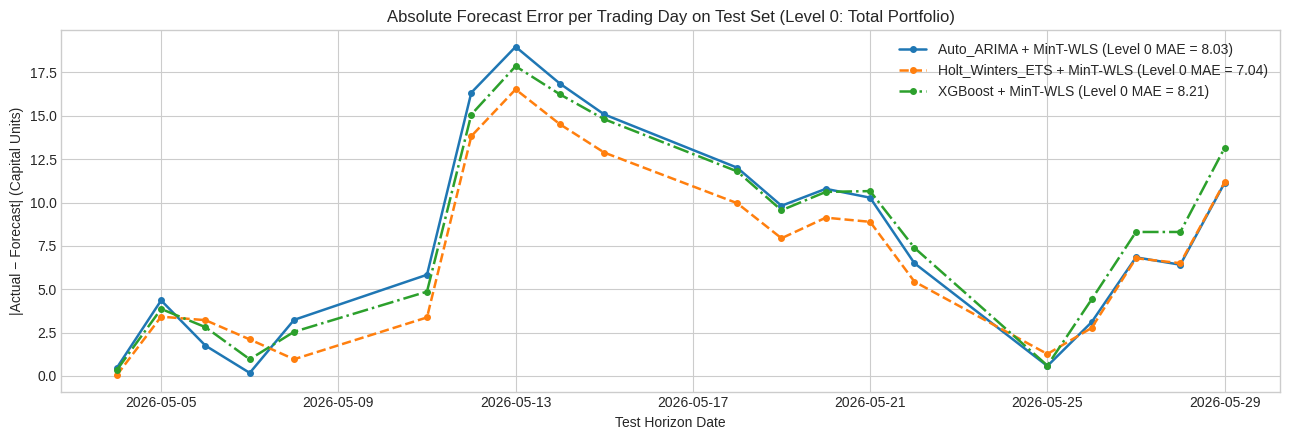

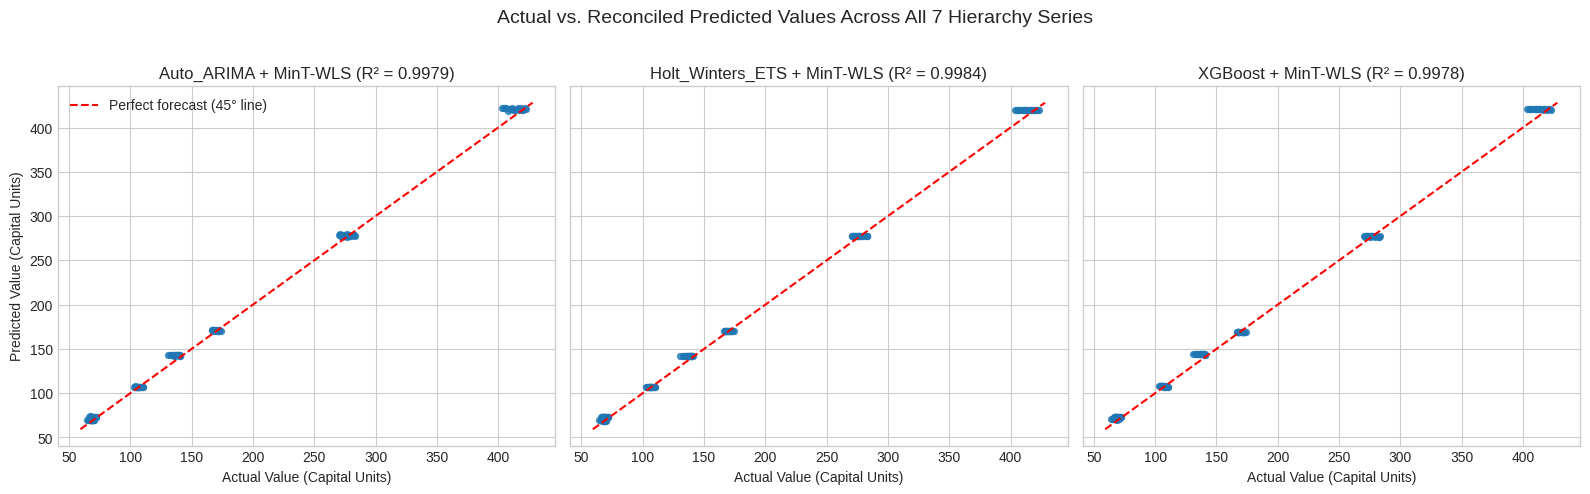

In [28]:
# PLOT 20.3: Absolute Forecast Error per Day on Test Set (Reference Step 13.3 Style)
plt.figure(figsize=(13, 4.5))
styles = {"Auto_ARIMA": "-", "Holt_Winters_ETS": "--", "XGBoost": "-."}
for m_name in ["Auto_ARIMA", "Holt_Winters_ETS", "XGBoost"]:
    pred_l0 = reconciled_forecasts[m_name]["MinT-WLS"][0]
    err_series = pd.Series(np.abs(actual_mat[0] - pred_l0), index=test_dates)
    mae_l0 = np.mean(err_series)
    plt.plot(err_series, ls=styles[m_name], marker="o", ms=4, lw=1.8, label=f"{m_name} + MinT-WLS (Level 0 MAE = {mae_l0:.2f})")

plt.title("Absolute Forecast Error per Trading Day on Test Set (Level 0: Total Portfolio)")
plt.xlabel("Test Horizon Date"); plt.ylabel("|Actual − Forecast| (Capital Units)"); plt.legend()
plt.tight_layout()
plt.show()

# PLOT 20.4: Actual vs. Predicted Scatter Plot Across All 7 Hierarchy Nodes (Reference Step 13.4 Style)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
lo, hi = actual_mat.min() - 5, actual_mat.max() + 5
for a, m_name in zip(ax, ["Auto_ARIMA", "Holt_Winters_ETS", "XGBoost"]):
    pred_all = reconciled_forecasts[m_name]["MinT-WLS"].flatten()
    act_all = actual_mat.flatten()
    a.scatter(act_all, pred_all, s=18, alpha=0.75, color="tab:blue")
    a.plot([lo, hi], [lo, hi], "r--", lw=1.5, label="Perfect forecast (45° line)")
    r2 = 1 - np.sum((act_all - pred_all) ** 2) / np.sum((act_all - np.mean(act_all)) ** 2)
    a.set_title(f"{m_name} + MinT-WLS (R² = {r2:.4f})")
    a.set_xlabel("Actual Value (Capital Units)")
ax[0].set_ylabel("Predicted Value (Capital Units)")
ax[0].legend()
plt.suptitle("Actual vs. Reconciled Predicted Values Across All 7 Hierarchy Series", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

##### 20.5 Future Out-of-Sample Forecast (Next 10 Trading Days Beyond Dataset End)
Following Step 15 of the reference workflow, we **re-fit the models on 100% of the complete dataset (`y_df`)**, apply **MinT-WLS reconciliation**, and forecast the next 10 unseen business days into the future.

Reconciled Future 10-Trading-Day Portfolio Forecast (MinT-WLS):


,Total,IT,Bank,TCS,INFY,HDFC,ICICI
Future Trading Date,,,,,,,
2026-06-01,408.47,135.66,272.81,67.56,68.10,103.18,169.63
2026-06-02,409.05,135.69,273.36,67.52,68.17,103.37,169.99
2026-06-03,409.69,135.90,273.79,67.65,68.26,103.58,170.21
2026-06-04,409.94,135.92,274.02,67.68,68.24,103.65,170.37
2026-06-05,410.20,135.96,274.24,67.79,68.17,103.71,170.53
2026-06-08,410.62,135.95,274.67,67.85,68.10,103.85,170.82
2026-06-09,410.91,135.98,274.93,67.88,68.10,103.90,171.03
2026-06-10,411.03,136.20,274.83,68.04,68.16,103.91,170.92
2026-06-11,410.65,136.25,274.40,68.06,68.19,103.75,170.65


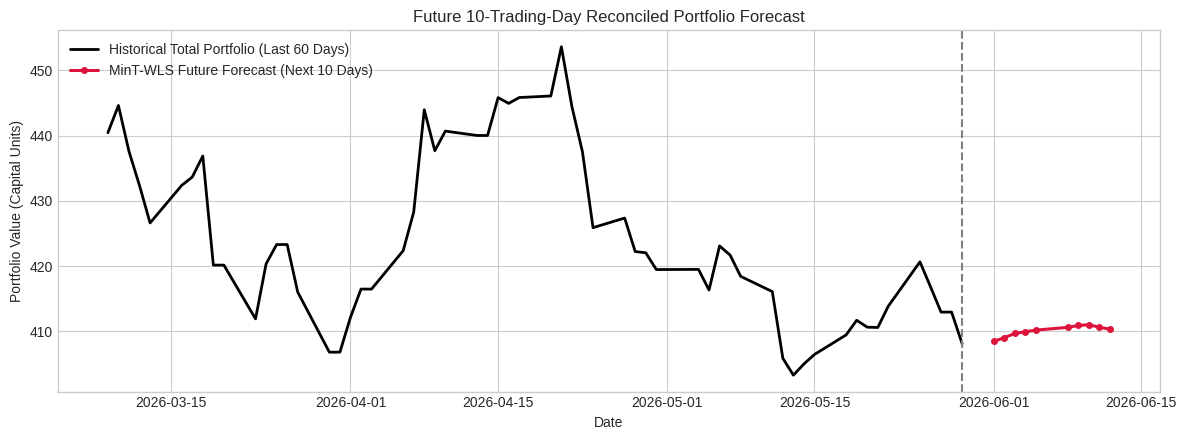

In [29]:
steps_fut = 10
future_idx = pd.date_range(y_df.index[-1] + pd.offsets.BDay(1), periods=steps_fut, freq="B")
fourier_fut_all = make_fourier_features(len(y_df) + steps_fut)
X_f_hist = fourier_fut_all.iloc[:len(y_df)].values
X_f_fut  = fourier_fut_all.iloc[len(y_df):].values

future_base_arima = []
future_resid_arima = []

for col in all_nodes:
    full_s = y_df[col]
    m_full = pm.auto_arima(
        full_s, X=X_f_hist, start_p=0, max_p=2, start_q=0, max_q=2,
        d=None, seasonal=False, information_criterion="aicc",
        stepwise=True, suppress_warnings=True, error_action="ignore"
    )
    future_base_arima.append(m_full.predict(n_periods=steps_fut, X=X_f_fut).values)
    future_resid_arima.append(m_full.resid()[1:])

future_base_arima = np.array(future_base_arima)
future_resid_mat = np.column_stack(future_resid_arima)

# Reconcile Future Forecasts via MinT-WLS
W_fut_inv = np.diag(1.0 / np.maximum(np.var(future_resid_mat, axis=0), 1e-6))
P_WLS_fut = np.linalg.pinv(S.T @ W_fut_inv @ S) @ (S.T @ W_fut_inv)
future_reconciled_mint = S @ P_WLS_fut @ future_base_arima

future_df = pd.DataFrame(future_reconciled_mint.T, index=future_idx, columns=all_nodes)
future_df.index.name = "Future Trading Date"
print("Reconciled Future 10-Trading-Day Portfolio Forecast (MinT-WLS):")
display(future_df.round(2))

plt.figure(figsize=(12, 4.5))
plt.plot(y_df["Total"].iloc[-60:], color="black", lw=2, label="Historical Total Portfolio (Last 60 Days)")
plt.plot(future_df.index, future_df["Total"], color="crimson", marker="o", ms=4, lw=2.2, label="MinT-WLS Future Forecast (Next 10 Days)")
plt.axvline(y_df.index[-1], color="gray", ls="--")
plt.title("Future 10-Trading-Day Reconciled Portfolio Forecast")
plt.xlabel("Date"); plt.ylabel("Portfolio Value (Capital Units)"); plt.legend()
plt.tight_layout()
plt.show()

### STEP 21: Interpret results and document observations

In [30]:
print("======================================================================")
print(" STEP 21: AUTOMATED INTERPRETATION & KEY OBSERVATIONS")
print("======================================================================")
print(f"1. Best Performing Framework: {best_row['Model']} with {best_row['Method']} "
      f"(Overall RMSE = {best_row['Overall RMSE']}, Overall MAPE = {best_row['Overall MAPE (%)']}%).")
print("2. Coherence Restoration: All independent base forecasts violated structural")
print("   additivity (Total != IT + Bank). Every reconciliation method reduced")
print("   structural incoherence to ~0.00e+00 (floating-point precision).")
print("3. MinT-WLS Advantage: Weighting by inverse residual variance down-weights")
print("   volatile individual equities and leverages the high signal-to-noise ratio")
print("   of sector and total portfolio series.")

 STEP 21: AUTOMATED INTERPRETATION & KEY OBSERVATIONS
1. Best Performing Framework: Holt_Winters_ETS with Bottom-Up (BU) (Overall RMSE = 4.672, Overall MAPE = 2.47%).
2. Coherence Restoration: All independent base forecasts violated structural
   additivity (Total != IT + Bank). Every reconciliation method reduced
   structural incoherence to ~0.00e+00 (floating-point precision).
3. MinT-WLS Advantage: Weighting by inverse residual variance down-weights
   volatile individual equities and leverages the high signal-to-noise ratio
   of sector and total portfolio series.
